# 2. Multi-Objective Optimization — MOMILP + AUGMECON2 (v2: giỏ hàng, DOS 2025)

Bước 2 của chuỗi **Demand → Multi-Objective Optimization → TOPSIS**.

**Khác bản 12/10 ở đâu (v2):** chỉ khác **ràng buộc sức chứa (2.4.3)**. Bản 12/10 dùng một DOS 2030 cho mỗi kho. Bản v2 dùng **DOS 2025 của 124 nhóm sản phẩm** tại từng kho, gộp theo **giỏ hàng** của từng nhóm khách: pallet giao cho khách nào thì mang đúng cơ cấu hàng khách đó mua. Biến, cầu, cân bằng luồng, `f1`, `f2`, `f3`, AUGMECON2 giữ nguyên.

- **Đọc:** `Model - Data used/` (kho, chi phí, lead time, `dos_2025.parquet`, `dos_2025_fill.parquet`, `demand_b2b.parquet`) và `Model Outputs/demand.parquet` (notebook 1).
- **Mô hình:** MILP tất định chọn mở/đóng kho (`Y_j`) và luồng hàng; cầu = `d_k` (pallet/năm, cột `DemandPallet`).
- **Mục tiêu:** `f1` tổng chi phí (min), `f2` số ngày giao trung bình mỗi pallet (min), `f3` CO2 (min).
- **Giải:** Pyomo + HiGHS (`appsi_highs`), AUGMECON2 → tập Pareto.
- **Ghi:** `Model Outputs/18-10-2027/` (parquet + CSV đọc được + hình), bản đọc được chép thêm vào `Model Outputs/Mẹ/`. Không đè kết quả 12/10.

**Thứ tự chạy:** từ trên xuống. Kiểm tra `min f1` (2.5.1) trước, rồi payoff table → AUGMECON2.

## 2.0 Setup

*(code: import thư viện, đọc dữ liệu)*

In [32]:
# ===== 2.0 SETUP =====
import pandas as pd                       # xử lý bảng
import numpy as np                        # tính toán
from pathlib import Path                  # ghép đường dẫn

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

IN = Path("../Model - Data used")         # data đã clean (2 notebook Validation)
OUT_IN = Path("../Model Outputs")         # nơi đọc demand.parquet (notebook 1)
OUT = OUT_IN / "18-10-2027"                # kết quả lần chạy đêm 18/10 (bản v2: giỏ hàng, DOS 2025), không đè bản 12/10
OUT.mkdir(exist_ok=True)

# Bảng tuyến kho -> khách: "day_du" = mọi kho × mọi nhóm (Decision_Log 4.3a), "cong_ty" = chỉ tuyến của công ty (để so sánh)
TUYEN = "day_du"
FILE_LM = "cost_lastmile_b2b_full.parquet" if TUYEN == "day_du" else "cost_lastmile_b2b.parquet"
FILE_TR = "cost_transfer_full.parquet" if TUYEN == "day_du" else "cost_transfer.parquet"      # tuyến kho -> kho (Decision_Log 4.3b)

DAYS_YEAR = 360                           # số ngày / năm khi đổi sức chứa ra thông lượng (giống công ty, Decision_Log 4.4)

# --- Đọc dữ liệu ---
fac = pd.read_parquet(IN / "facility_master.parquet")         # 53 kho: loại kho, sức chứa, tiền thuê, phí handling
dos = pd.read_parquet(IN / "dos_2025.parquet")                # DOS 2025 mỗi kho (trung bình có trọng số pallet xuất 2025), chỉ dùng cho kiểm tra 2.2.2
tr = pd.read_parquet(IN / FILE_TR)                   # tuyến kho -> kho, IDR/pallet (giá 2025)
lm = pd.read_parquet(IN / FILE_LM)                            # tuyến kho -> nhóm khách, IDR/pallet (giá 2025)
lead = pd.read_parquet(IN / "lead_time.parquet")              # thời gian giao + khoảng cách mỗi tuyến
dem = pd.read_parquet(OUT_IN / "demand.parquet")                 # cầu mỗi nhóm khách, pallet/năm (Demand.ipynb)

for ten, bang in [("kho", fac), ("DOS", dos), ("transfer", tr), ("last-mile", lm), ("lead time", lead), ("cầu", dem)]:
    print(f"{ten:10s}: {len(bang):>6,} dòng")

kho       :     53 dòng
DOS       :     53 dòng
transfer  :  1,148 dòng
last-mile : 147,387 dòng
lead time : 15,139 dòng
cầu       :  3,346 dòng


## 2.1 Problem description

### 2.1.1 Network structure and assumptions

**Mạng lưới phân phối:**

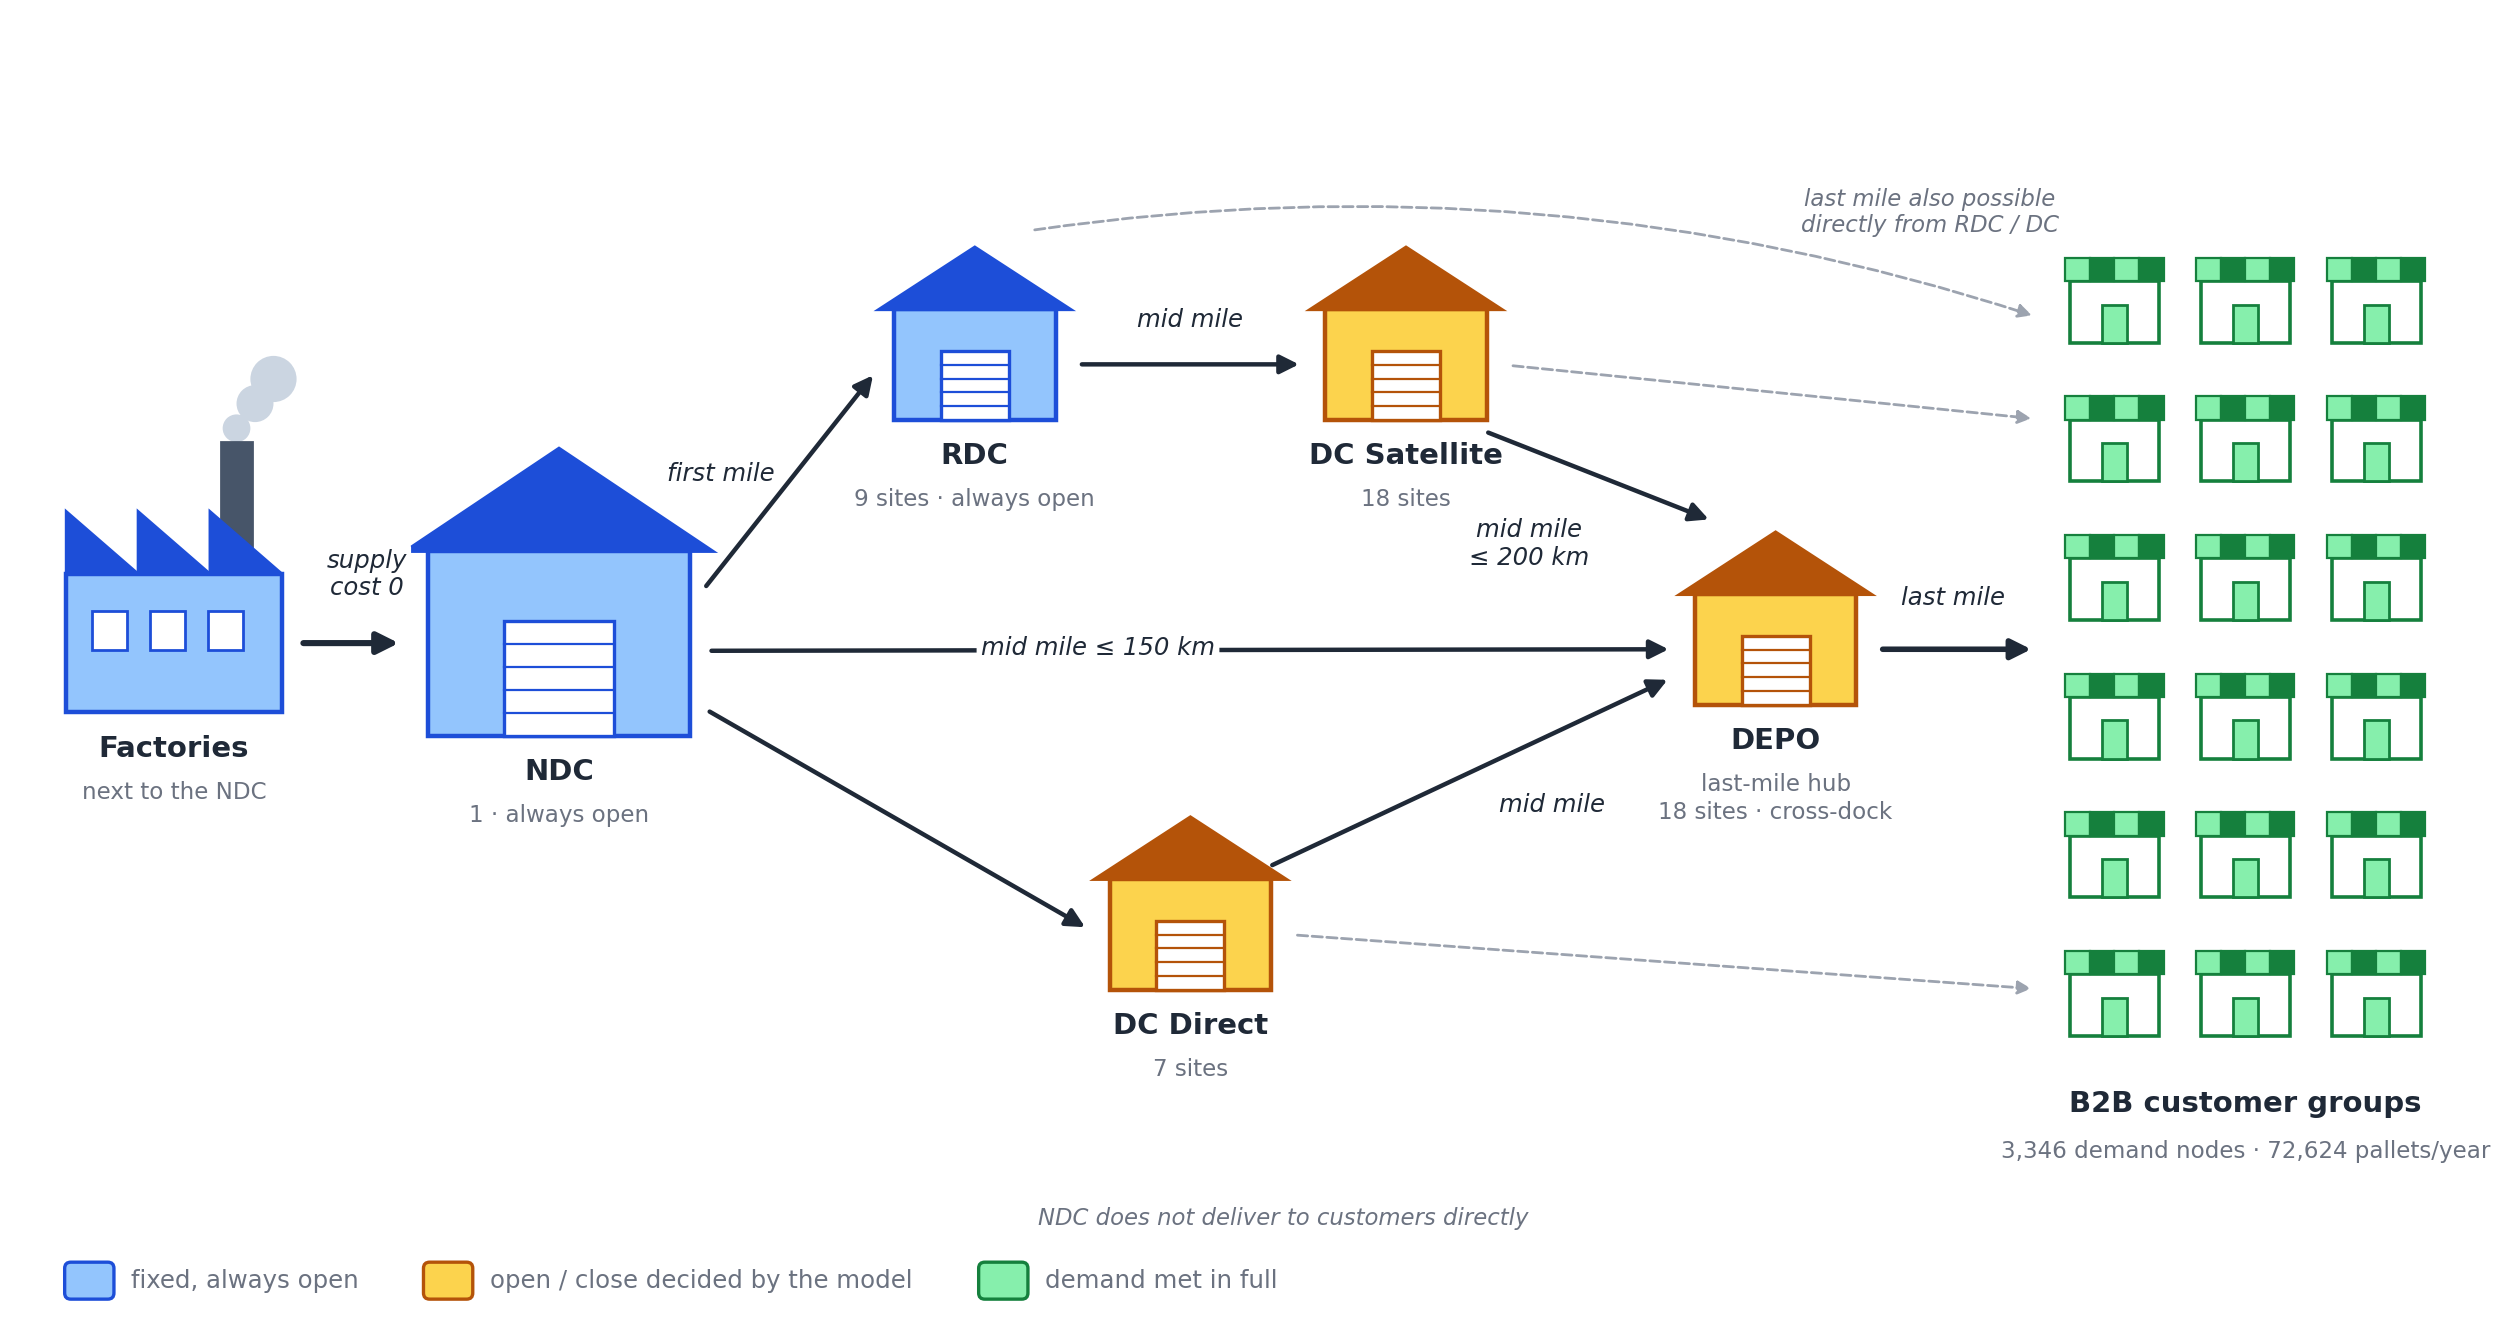

*Hình cũng được lưu ở `Model Outputs/figures/network_structure.png` để đưa vào luận văn.*

Luồng hàng theo sơ đồ mạng của công ty:

- **Nhà máy → NDC** (phí 0). **NDC** luôn mở.
- **First mile:** NDC → RDC hoặc NDC → DC Direct.
- **Mid mile:** RDC → DC Satellite → DEPO (last-mile hub, ≤ 200 km), hoặc DC Direct → DEPO.
- **Last mile:** DEPO → khách. RDC và DC cũng giao thẳng được cho khách nếu bảng giá có tuyến đó.
- **NDC không giao thẳng cho khách B2B** (Decision_Log 4.3f). NDC chỉ cấp hàng cho RDC, DC Direct và DEPO trong 150 km.

Luồng hàng **đi theo đúng phân tầng** trên (Decision_Log 4.3d): không có tuyến ngang hay ngược, DC Satellite chỉ nhận hàng từ RDC cùng đảo (4.3e), chặng cuối chỉ giao trong cùng đảo (4.3c). **NDC và 9 RDC luôn mở**; **43 kho** còn lại (7 DC Direct, 18 DC Satellite, 18 DEPO) được mô hình **tự chọn mở hay đóng** (4.2c).

**Giả định:**

| # | Giả định | Decision_Log |
|---|---|---|
| 1 | **Một kỳ = một năm** (dữ liệu 2025). Cầu, chi phí, sức chứa đều tính theo năm | 2.4 |
| 2 | **Luồng hàng là một sản phẩm gộp**, đo bằng **pallet** (mỗi sản phẩm đổi cái → pallet trước khi cộng). **Khác biệt giữa 124 nhóm sản phẩm** đi vào mô hình qua **giỏ hàng** của từng nhóm khách: sức chứa dùng DOS 2025 của từng nhóm sản phẩm, CO2 dùng tấn/pallet theo cơ cấu hàng của khách. Giả định: pallet giao cho khách nào mang đúng cơ cấu hàng khách đó mua | 2.3, 4.5 |
| 3 | Chỉ kênh **B2B**, chỉ **Indonesia** | 2.1, 2.2 |
| 4 | **Cầu tất định**: mỗi nhóm khách một con số pallet/năm. Không xét độ nhạy cầu; biến động cầu là giới hạn của mô hình | 1.3, 6.1 |
| 5 | Nhà máy nằm cạnh NDC: chặng nhà máy → NDC **phí 0, không giới hạn** hàng | 4.1 |
| 6 | Chỉ xét **kho đang có**, không xây kho mới. NDC và 9 RDC luôn mở | 4.2, 4.2a, 4.2c |
| 7 | **Tuyến kho → khách**: mọi cặp kho × nhóm khách **cùng đảo** (giá thật nếu có, còn lại ước lượng theo km). **Tuyến kho → kho**: theo phân tầng | 4.3a–4.3e |
| 8 | **Phải giao đủ 100% cầu**, không cho thiếu hàng | — |
| 9 | Một nhóm khách **có thể nhận hàng từ nhiều kho** (không bắt buộc 1 kho duy nhất) | — |
| 10 | **DEPO** là kho trung chuyển (cross-dock, DOS = 0): không giới hạn sức chứa | 4.5 |
| 12 | **Sức chứa** tính theo **tồn kho trung bình** = lượng xuất × DOS / 360, với **DOS lịch sử 2025** theo kho × nhóm sản phẩm (ô thiếu fill bằng trung vị cùng loại kho) | 4.4, 4.5 |
| 11 | Mọi chi phí ở **mặt bằng giá 2025** (giá 2030 của công ty đã được quy về 2025) | 5.7 |

### 2.1.2 Sets and indices

| Tập | Chỉ số | Gồm những gì | Số phần tử |
|---|---|---|---|
| $J$ | $i, j, l$ | Tất cả kho | 53 |
| $J^{dec} \subset J$ | $j$ | Kho mô hình chọn mở/đóng (trừ NDC và 9 RDC) | 43 |
| $K$ | $k$ | Nhóm khách B2B (nút cầu) | 3,346 |
| $A^{tr} \subset J \times J$ | $(i, j)$ | Tuyến kho → kho theo phân tầng | 96 |
| $A^{lm} \subset J \times K$ | $(j, k)$ | Tuyến kho → nhóm khách cùng đảo | ≈ 53,000 |
| $G$ | $g$ | Nhóm sản phẩm của Company (chỉ dùng để tính tham số giỏ hàng, không có biến riêng) | 124 |

Ký hiệu ngắn: $J^{ra}_j$ = các kho mà kho $j$ chở sang được; $J^{vao}_j$ = các kho chở được vào kho $j$; $K_j$ = các nhóm khách kho $j$ giao được; $J_k$ = các kho giao được cho nhóm $k$.

### 2.1.3 Parameters

| Ký hiệu | Ý nghĩa | Đơn vị | Nguồn (cột) | Decision_Log |
|---|---|---|---|---|
| $d_k$ | Cầu của nhóm khách $k$ | pallet/năm | `demand.parquet` (`DemandPallet`) | 5.1, 5.9 |
| $F_j$ | Tiền thuê kho $j$ cả năm | IDR/năm | `facility_master` (`FixedStorageCost`) | 4.4b |
| $h_j$ | Phí handling 1 pallet xuất khỏi kho $j$ | IDR/pallet | `facility_master` (`B2BHandlingCostPerPallet`) | 3.1 |
| $c^{tr}_{ij}$ | Phí chở 1 pallet từ kho $i$ sang kho $j$ | IDR/pallet | `cost_transfer` (`CostPerPallet`) | 4.3, 5.7 |
| $c^{lm}_{jk}$ | Phí chở 1 pallet từ kho $j$ tới nhóm $k$ | IDR/pallet | `cost_lastmile_b2b` (`CostPerPallet`) | 5.7 |
| $C_j$ | Số chỗ chứa của kho $j$ (pallet cùng lúc) | pallet | `facility_master` (`CapacityInPallet`) | 4.4 |
| $DOS_{jg}$ | Số ngày nhóm sản phẩm $g$ nằm trong kho $j$, năm 2025 | ngày | `dos_2025_fill` (`DOS`) | 4.5 |
| $a_{kg}$ | Tỷ lệ nhóm $g$ trong giỏ hàng của khách $k$ (theo pallet) | — | `demand_b2b` | 2.3 |
| $DOS_{jk}$ | Số ngày pallet giao cho khách $k$ nằm trong kho $j$ $= \sum_g a_{kg} DOS_{jg}$ | ngày | tính ở 2.4.3 | 4.5 |

Dùng cho `f2`, `f3` (thêm sau):

| Ký hiệu | Ý nghĩa | Đơn vị | Nguồn |
|---|---|---|---|
| $LT_{jk}$ | Thời gian giao từ kho $j$ tới nhóm $k$ | ngày | `lead_time` (`TotalLeadTimeInDays`) |
| $km_{ij}$, $km_{jk}$ | Khoảng cách đường bộ / đường biển | km | `lead_time` |
| $w_k$ | Tấn trên 1 pallet của nhóm $k$ | tấn/pallet | `demand.parquet` (`TonPerPallet`) |

### 2.1.4 Decision variables

| Biến | Loại | Ý nghĩa | Đơn vị |
|---|---|---|---|
| $Y_j$, $j \in J^{dec}$ | nhị phân (0/1) | 1 = mở kho $j$, 0 = đóng. NDC cố định $Y_{NDC} = 1$ | — |
| $T_{ij}$, $(i,j) \in A^{tr}$ | liên tục, ≥ 0 | Số pallet chở từ kho $i$ sang kho $j$ | pallet/năm |
| $X_{jk}$, $(j,k) \in A^{lm}$ | liên tục, ≥ 0 | Số pallet kho $j$ giao cho nhóm khách $k$ | pallet/năm |

Biến phụ (tính từ biến chính, không phải quyết định riêng): lượng xuất khỏi kho $j$, $\;Out_j = \sum_{l \in J^{ra}_j} T_{jl} + \sum_{k \in K_j} X_{jk}$, dùng cho phí handling và sức chứa.

Mô hình có 43 biến nhị phân và khoảng 53 nghìn biến liên tục.

## 2.2 Data preparation and feasibility check

### 2.2.1 Parameter construction

*(code: tạo bảng tham số cho mô hình)*

In [33]:
# ===== 2.2.1 TẠO THAM SỐ CHO MÔ HÌNH =====
# Đọc lại bảng kho và 2 bảng tuyến mỗi lần chạy ô này -> chạy lại bao nhiêu lần cũng không lỗi
fac = pd.read_parquet(IN / "facility_master.parquet").drop(columns=["DOS"], errors="ignore")
tr = pd.read_parquet(IN / FILE_TR)
lm = pd.read_parquet(IN / FILE_LM)

# --- Tập kho: NDC + 9 RDC luôn mở (Decision_Log 4.2c), DC Direct / DC Satellite / DEPO do mô hình chọn ---
fac = fac.merge(dos[["LocationID", "DOS"]], on="LocationID", how="left", validate="one_to_one")
assert fac["DOS"].notna().all(), "Có kho thiếu DOS"
loai = fac.set_index("LocationID")["FacilityType"]                       # loại kho theo mã kho
J = sorted(fac["LocationID"])                                            # 53 kho
NDC = fac.loc[fac["FacilityType"] == "NDC", "LocationID"].item()         # mã NDC
J_FIXED = sorted(loai[loai.isin(["NDC", "RDC"])].index)                  # kho luôn mở: NDC + RDC
J_dec = sorted(set(J) - set(J_FIXED))                                    # kho mô hình chọn mở / đóng
print(f"Kho luôn mở: {len(J_FIXED)} | kho mô hình chọn: {len(J_dec)}")
print(loai.value_counts().to_string())

# --- Tập nhóm khách K ---
K = sorted(dem["ShipToGroupID"])
d = dem.set_index("ShipToGroupID")["DemandPallet"]                       # d_k: pallet/năm

# --- Tuyến kho -> kho: chỉ giữ luồng phân tầng theo sơ đồ CEL (Decision_Log 4.3d) ---
# Giới hạn km vào DEPO (NDC ≤ 150, kho khác ≤ 200) đã có sẵn trong bảng tuyến (4.3b)
LUONG_KHO = {("NDC", "RDC"), ("NDC", "DC Direct"), ("NDC", "DEPO"),
             ("RDC", "DC Satellite"), ("RDC", "DEPO"),
             ("DC Direct", "DEPO"), ("DC Satellite", "DEPO")}
tr["LoaiTu"], tr["LoaiDen"] = tr["OriginID"].map(loai), tr["DestinationID"].map(loai)
tr["Giu"] = [(a, b) in LUONG_KHO for a, b in zip(tr["LoaiTu"], tr["LoaiDen"])]
print("\nTuyến kho -> kho theo cặp loại (Giu = True: giữ lại):")
print(tr.groupby(["LoaiTu", "LoaiDen", "Giu"]).size().rename("SoTuyen").reset_index().to_string(index=False))
tr = tr[tr["Giu"]].drop(columns=["LoaiTu", "LoaiDen", "Giu"]).copy()

# --- RDC -> DC Satellite: mỗi Satellite chỉ nhận hàng từ RDC cùng đảo (Decision_Log 4.3e) ---
# Đảo không có RDC (Bali - Nusra, Maluku): Satellite chỉ nhận từ RDC gần nhất (đường chim bay).
# Lý do: không có luật này, RDC Sulawesi giao cho Satellite ở Kalimantan và ngược lại, dù đảo đó có RDC riêng.
dao_kho_tr = fac.set_index("LocationID")["MainIsland"]                   # đảo của mỗi kho
toa_kho = fac.set_index("LocationID")[["Latitude", "Longitude"]].astype(float)

def km_chim_bay(a, b):
    # khoảng cách đường chim bay (km) giữa kho a và kho b (công thức haversine)
    la1, lo1 = np.radians(toa_kho.loc[a])
    la2, lo2 = np.radians(toa_kho.loc[b])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))

la_rs = (tr["OriginID"].map(loai) == "RDC") & (tr["DestinationID"].map(loai) == "DC Satellite")
rs = tr[la_rs].copy()
rs["DaoRDC"] = rs["OriginID"].map(dao_kho_tr)
rs["DaoSat"] = rs["DestinationID"].map(dao_kho_tr)
rs["CungDao"] = rs["DaoRDC"] == rs["DaoSat"]
rs["Km"] = [km_chim_bay(a, b) for a, b in zip(rs["OriginID"], rs["DestinationID"])]
co_cung_dao = rs.groupby("DestinationID")["CungDao"].transform("any")    # Satellite có ít nhất 1 RDC cùng đảo?
gan_nhat = rs["Km"] == rs.groupby("DestinationID")["Km"].transform("min")  # RDC gần nhất của mỗi Satellite
rs["Giu"] = np.where(co_cung_dao, rs["CungDao"], gan_nhat)

print(f"\nTuyến RDC -> DC Satellite: {len(rs)} -> giữ {rs['Giu'].sum()} | bỏ {(~rs['Giu']).sum()} (khác đảo)")
print(rs[rs["Giu"]].sort_values(["DaoSat", "DestinationID"])[["OriginID", "DestinationID", "DaoRDC", "DaoSat", "Km"]]
      .round(0).head(10).to_string(index=False))
print("Satellite trên đảo không có RDC -> RDC gần nhất:")
print(rs[rs["Giu"] & ~rs["CungDao"]][["OriginID", "DestinationID", "DaoRDC", "DaoSat", "Km"]].round(0).to_string(index=False))
tr = tr.drop(index=rs.index[~rs["Giu"]])                                 # bỏ tuyến RDC -> Satellite khác đảo
assert set(rs.loc[rs["Giu"], "DestinationID"]) == set(rs["DestinationID"]), "Có Satellite mất hết tuyến từ RDC"

# Kiểm tra: kho nào (trừ NDC) không còn tuyến nhận hàng -> kho đó không bao giờ dùng được
khong_vao = sorted(set(J) - {NDC} - set(tr["DestinationID"]))
print(f"\nKho không còn tuyến nhận hàng: {len(khong_vao)}")
print(fac.loc[fac["LocationID"].isin(khong_vao), ["LocationID", "FacilityType", "MainIsland"]].head(10).to_string(index=False))
assert not set(khong_vao) & set(J_FIXED), "Có RDC luôn mở nhưng không có tuyến nhận hàng"

# --- Tuyến kho -> khách ---
lm = lm[lm["DestinationID"].isin(K)].copy()                              # chỉ nhóm còn trong cầu
lm_truoc = len(lm)

# (a) NDC không giao thẳng cho nhóm khách B2B (Decision_Log 4.3f, đổi 2026-10-17): bỏ mọi tuyến NDC -> khách.
#     NDC chỉ cấp hàng cho RDC, DC Direct và DEPO trong 150 km (tuyến kho -> kho, 4.3d)
lm = lm[lm["OriginID"] != NDC].copy()
print(f"\nTuyến last-mile: {lm_truoc:,} -> {len(lm):,} sau khi bỏ tuyến NDC -> khách")

# (b) Chỉ giao cùng đảo (Decision_Log 4.3c); nhóm không có kho nào cùng đảo thì giữ tuyến khác đảo
dao_kho = fac.set_index("LocationID")["MainIsland"]                      # đảo của mỗi kho
dao_khach = dem.set_index("ShipToGroupID")["MainIsland"]                 # đảo của mỗi nhóm khách
print("Đảo của kho  :", sorted(dao_kho.unique()))                         # 2 danh sách phải cùng cách viết tên đảo
print("Đảo của khách:", sorted(dao_khach.unique()))
assert dao_kho.notna().all() and dao_khach.notna().all(), "Có kho / nhóm khách thiếu tên đảo"
lm["CungDao"] = lm["OriginID"].map(dao_kho).values == lm["DestinationID"].map(dao_khach).values
co_kho_cung_dao = set(lm.loc[lm["CungDao"], "DestinationID"])            # nhóm có ít nhất 1 kho cùng đảo
giu = lm["CungDao"] | ~lm["DestinationID"].isin(co_kho_cung_dao)        # giữ: cùng đảo + mọi tuyến của nhóm ngoại lệ
ngoai_le = sorted(set(lm["DestinationID"]) - co_kho_cung_dao)
print(f"Bỏ tuyến khác đảo: {(~giu).sum():,} | nhóm không có kho cùng đảo: {len(ngoai_le)} "
      f"(cầu {d[ngoai_le].sum():,.0f} pallet/năm)")
print(lm.loc[lm["DestinationID"].isin(ngoai_le), ["OriginID", "DestinationID", "DistanceInKM"]].head(10).to_string())
lm = lm[giu].drop(columns="CungDao").copy()

assert set(lm["DestinationID"]) == set(K), "Có nhóm khách không có kho nào giao tới"
assert set(lm["OriginID"]) <= set(J) and set(tr["OriginID"]) <= set(J) and set(tr["DestinationID"]) <= set(J)

# --- Tham số mỗi kho ---
fac = fac.set_index("LocationID")
f_fixed = fac["FixedStorageCost"]                                        # tiền thuê kho, IDR/năm (Decision_Log 4.4b)
h = fac["B2BHandlingCostPerPallet"]                                      # phí handling, IDR/pallet hàng xuất ra
# Sức chứa thông lượng (pallet/năm) = chỗ chứa × 360 / DOS. DEPO: DOS = 0 (cross-dock) -> không giới hạn
cap = pd.Series(np.where(fac["DOS"] > 0, fac["CapacityInPallet"] * DAYS_YEAR / fac["DOS"].where(fac["DOS"] > 0), np.inf),
                index=fac.index, name="CapYear")

print(f"\nKho: {len(J)} (luôn mở: {len(J_FIXED)}, quyết định: {len(J_dec)}) | nhóm khách: {len(K):,} | "
      f"tuyến transfer: {len(tr):,} | tuyến last-mile: {len(lm):,}")
print(f"Tổng cầu: {d.sum():,.0f} pallet/năm | tiền thuê kho luôn mở: {f_fixed[J_FIXED].sum() / 1e9:,.1f} tỷ IDR/năm")


Kho luôn mở: 10 | kho mô hình chọn: 43
FacilityType
DC Satellite    18
DEPO            18
RDC              9
DC Direct        7
NDC              1

Tuyến kho -> kho theo cặp loại (Giu = True: giữ lại):
      LoaiTu      LoaiDen   Giu  SoTuyen
   DC Direct    DC Direct False       42
   DC Direct DC Satellite False      125
   DC Direct         DEPO  True       17
   DC Direct          RDC False       63
DC Satellite    DC Direct False      121
DC Satellite DC Satellite False      277
DC Satellite         DEPO  True       11
DC Satellite          RDC False      151
         NDC    DC Direct  True        7
         NDC DC Satellite False       18
         NDC         DEPO  True        2
         NDC          RDC  True        9
         RDC    DC Direct False       63
         RDC DC Satellite  True      161
         RDC         DEPO  True        9
         RDC          RDC False       72

Tuyến RDC -> DC Satellite: 161 -> giữ 41 | bỏ 120 (khác đảo)
OriginID DestinationID DaoRDC       Dao

In [34]:
# ===== KIỂM TRA: TUYẾN NDC -> KHÁCH CÓ KM KHÔNG, XA NHẤT BAO NHIÊU =====
ndc_lm = lm[lm["OriginID"] == NDC]                                       # tuyến NDC giao thẳng khách
print(f"Số tuyến NDC -> khách: {len(ndc_lm):,} | thiếu km: {ndc_lm['DistanceInKM'].isna().sum():,}")
print(ndc_lm["DistanceInKM"].describe().round(1).to_string())
print(ndc_lm.sort_values("DistanceInKM", ascending=False)[["DestinationID", "DistanceInKM"]].head(10).to_string())


Số tuyến NDC -> khách: 0 | thiếu km: 0
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Empty DataFrame
Columns: [DestinationID, DistanceInKM]
Index: []


In [35]:
# ===== KIỂM TRA: GIÁ LAST-MILE CÓ TỈ LỆ VỚI KM KHÔNG =====
km = lead[["OriginID", "DestinationID", "DistanceInKM"]].drop_duplicates(["OriginID", "DestinationID"])
lm_that = lm[~lm["IsEstimated"]] if "IsEstimated" in lm.columns else lm      # chỉ tuyến có giá thật của công ty
g = lm_that[["OriginID", "DestinationID", "CostPerPallet"]].merge(km, on=["OriginID", "DestinationID"], how="left")
print(f"Tuyến thiếu km: {g['DistanceInKM'].isna().sum()} | km = 0: {(g['DistanceInKM'] <= 0).sum()}")
g = g[g["DistanceInKM"] > 0].copy()
g["DonGia"] = g["CostPerPallet"] / g["DistanceInKM"]                       # đ / pallet / km

# (1) Mỗi kho có bao nhiêu tuyến
so_tuyen = g.groupby("OriginID").size()
print(f"\n(1) Số tuyến mỗi kho: ít nhất {so_tuyen.min()} | trung vị {so_tuyen.median():.0f} | kho < 10 tuyến: {(so_tuyen < 10).sum()}")

# (2) Đơn giá có ổn định trong từng kho không (hệ số biến thiên: nhỏ = ổn định)
on_dinh = g.groupby("OriginID")["DonGia"].agg(lambda s: s.std() / s.mean())
print(f"(2) Độ dao động đơn giá trong mỗi kho (CV): trung vị {on_dinh.median():.2f} | kho CV > 0.5: {(on_dinh > 0.5).sum()}")

# (3) Giá có tỉ lệ thẳng với km không: so tuyến ngắn vs dài
g["NhomKm"] = pd.cut(g["DistanceInKM"], [0, 10, 25, 50, 100, 200, 500, 1e5])
print("\n(3) Đơn giá trung vị theo độ dài tuyến (đ/pallet/km):")
print(g.groupby("NhomKm", observed=True)["DonGia"].median().round(0).to_string())


Tuyến thiếu km: 0 | km = 0: 0

(1) Số tuyến mỗi kho: ít nhất 20 | trung vị 236 | kho < 10 tuyến: 0
(2) Độ dao động đơn giá trong mỗi kho (CV): trung vị 0.37 | kho CV > 0.5: 12

(3) Đơn giá trung vị theo độ dài tuyến (đ/pallet/km):
NhomKm
(0.0, 10.0]          20841.0
(10.0, 25.0]         21789.0
(25.0, 50.0]         23917.0
(50.0, 100.0]        23452.0
(100.0, 200.0]       23452.0
(200.0, 500.0]       16387.0
(500.0, 100000.0]     7991.0


### 2.2.2 Capacity versus demand

*(code: sức chứa NDC và các kho so với cầu)*

In [36]:
# ===== 2.2.2 SỨC CHỨA SO VỚI CẦU =====
# Câu hỏi: sức chứa có bao giờ là giới hạn không? Nếu không, mở/đóng kho chỉ do tiền thuê vs phí chở quyết định
bang = pd.DataFrame({"FacilityType": fac["FacilityType"], "MainIsland": fac["MainIsland"],
                     "Cho_chua": fac["CapacityInPallet"], "DOS": fac["DOS"], "CapYear": cap})

# (a) Theo loại kho: số kho, sức chứa thông lượng (pallet/năm)
print("(a) Sức chứa thông lượng theo loại kho (pallet/năm, DEPO = không giới hạn):")
print(bang.replace(np.inf, np.nan).groupby("FacilityType")["CapYear"].agg(["count", "min", "median", "max", "sum"]).round(0).to_string())

# (b) Riêng NDC so với toàn bộ cầu: mọi hàng đều xuất phát từ NDC, nên NDC phải đủ chỗ cho tất cả
print(f"\n(b) NDC: {cap[NDC]:,.0f} pallet/năm = {cap[NDC] / d.sum():.1f} lần tổng cầu ({d.sum():,.0f})")

# (c) Mỗi kho: nếu nó giao cho MỌI nhóm nó có tuyến tới, cầu tối đa là bao nhiêu, so với sức chứa
cau_toi_da = lm.assign(d=lm["DestinationID"].map(d)).groupby("OriginID")["d"].sum()
bang["Cau_toi_da"] = cau_toi_da.reindex(bang.index).fillna(0)
bang["Ty_le"] = bang["Cau_toi_da"] / bang["CapYear"]                    # > 1: kho có thể bị đầy
co_the_day = bang[(bang["Ty_le"] > 1) & np.isfinite(bang["CapYear"])].sort_values("Ty_le", ascending=False)
print(f"\n(c) Kho có thể bị đầy (cầu tối đa > sức chứa): {len(co_the_day)} / {np.isfinite(cap).sum()} kho có giới hạn")
print(co_the_day[["FacilityType", "MainIsland", "Cho_chua", "DOS", "CapYear", "Cau_toi_da", "Ty_le"]].round(2).to_string())

# (d) Theo đảo: tổng sức chứa các kho trên đảo so với cầu của đảo (không tính NDC, DEPO)
cau_dao = dem.groupby("MainIsland")["DemandPallet"].sum()
cap_dao = bang[(bang.index != NDC) & np.isfinite(bang["CapYear"])].groupby("MainIsland")["CapYear"].sum()
print("\n(d) Theo đảo: cầu vs sức chứa (không tính NDC và DEPO):")
print(pd.DataFrame({"Cau": cau_dao, "Suc_chua": cap_dao, "Lan": cap_dao / cau_dao}).round(1).to_string())

(a) Sức chứa thông lượng theo loại kho (pallet/năm, DEPO = không giới hạn):
              count       min    median       max       sum
FacilityType                                               
DC Direct         7    1318.0    6191.0    9115.0   40792.0
DC Satellite     18     284.0    1965.0    4525.0   39879.0
DEPO              0       NaN       NaN       NaN       0.0
NDC               1  169551.0  169551.0  169551.0  169551.0
RDC               9    5058.0    6563.0   14877.0   66544.0

(b) NDC: 169,551 pallet/năm = 2.3 lần tổng cầu (72,624)

(c) Kho có thể bị đầy (cầu tối đa > sức chứa): 31 / 35 kho có giới hạn
            FacilityType    MainIsland  Cho_chua    DOS   CapYear  Cau_toi_da  Ty_le
LocationID                                                                          
MWH_D35     DC Satellite          Java     128.0  23.50   1960.71    43730.20  22.30
MWH_D33     DC Satellite       Sumatra      73.0  41.24    637.20    13858.71  21.75
MWH_D05     DC Satellite       Suma

### 2.2.3 Single-source demand groups

*(code: các nhóm chỉ có 1 kho phục vụ)*

In [37]:
# ===== 2.2.3 NHÓM KHÁCH CHỈ CÓ 1 KHO GIAO TỚI =====
# Nếu nhóm k chỉ có 1 kho j giao tới, mô hình BUỘC phải mở j (vì phải đáp ứng hết cầu).
# Rủi ro: mở cả một kho (hàng tỷ IDR/năm) chỉ để giao vài pallet cho nhóm tí hon
so_kho = lm.groupby("DestinationID")["OriginID"].nunique()               # số kho giao tới mỗi nhóm
mot_kho = lm[lm["DestinationID"].isin(so_kho[so_kho == 1].index)]        # các tuyến duy nhất
print(f"Nhóm chỉ có 1 kho: {len(mot_kho):,} nhóm | cầu: {d[mot_kho['DestinationID']].sum():,.0f} pallet/năm "
      f"({d[mot_kho['DestinationID']].sum() / d.sum():.1%})")

# Theo kho: kho nào là kho duy nhất của bao nhiêu nhóm, cầu bao nhiêu, tiền thuê bao nhiêu
theo_kho = (mot_kho.assign(d=mot_kho["DestinationID"].map(d))
            .groupby("OriginID").agg(so_nhom=("DestinationID", "size"), cau=("d", "sum")))
if theo_kho.empty:                                                        # không còn nhóm nào chỉ có 1 kho
    print("Không có kho nào bị buộc mở.")
else:
  theo_kho["FacilityType"] = fac["FacilityType"]
  theo_kho["MainIsland"] = fac["MainIsland"]
  theo_kho["Tien_thue_ty"] = f_fixed[theo_kho.index] / 1e9                # tỷ IDR/năm
  theo_kho["Thue_moi_pallet"] = f_fixed[theo_kho.index] / theo_kho["cau"]   # IDR tiền thuê / 1 pallet của các nhóm này
  theo_kho["La_NDC"] = theo_kho.index == NDC
  print("\nKho bị buộc mở (sắp theo tiền thuê / pallet, cao = đáng ngờ):")
  print(theo_kho.sort_values("Thue_moi_pallet", ascending=False).round(2).to_string())
  print(f"\nSố kho bị buộc mở (không tính NDC): {(~theo_kho['La_NDC']).sum()} / {len(J_dec)} kho quyết định")
  print(f"So sánh: phí last-mile trung vị = {lm['CostPerPallet'].median():,.0f} IDR/pallet")

Nhóm chỉ có 1 kho: 0 nhóm | cầu: 0 pallet/năm (0.0%)
Không có kho nào bị buộc mở.


## 2.3 Objective functions

### 2.3.1 f1 – Total cost

Tổng chi phí một năm (IDR/năm), đổi ra **tỷ IDR** cho dễ đọc và để solver tính ổn định hơn:

$$f_1 = \underbrace{\sum_{j} F_j\,Y_j}_{\text{thuê kho}} + \underbrace{\sum_{(i,j)} c^{tr}_{ij}\,T_{ij}}_{\text{chở kho→kho}} + \underbrace{\sum_{(j,k)} c^{lm}_{jk}\,X_{jk}}_{\text{chở kho→khách}} + \underbrace{\sum_{j} h_j \Big(\sum_{l} T_{jl} + \sum_{k} X_{jk}\Big)}_{\text{handling hàng xuất ra}}$$

| Ký hiệu | Nghĩa | Đơn vị | Nguồn |
|---|---|---|---|
| $Y_j$ | 1 = mở kho $j$, 0 = đóng (NDC luôn = 1) | — | biến |
| $T_{ij}$ | pallet chở từ kho $i$ sang kho $j$ | pallet/năm | biến |
| $X_{jk}$ | pallet kho $j$ giao cho nhóm khách $k$ | pallet/năm | biến |
| $F_j$ | tiền thuê kho cả năm (`FixedStorageCost`) | IDR/năm | Decision_Log 4.4b |
| $c^{tr}_{ij}$, $c^{lm}_{jk}$ | phí chở 1 pallet trên tuyến | IDR/pallet | 5.7 |
| $h_j$ | phí handling 1 pallet xuất khỏi kho $j$ | IDR/pallet | 3.1 |

Chặng nhà máy → NDC có phí 0 (Decision_Log 4.1) nên không cần biến.

In [38]:
# ===== 2.3.1 DỰNG MÔ HÌNH: TẬP, BIẾN, CHI PHÍ f1 =====
import pyomo.environ as pyo

TY = 1e9                                                                 # đổi IDR -> tỷ IDR
A_tr = list(zip(tr["OriginID"], tr["DestinationID"]))                    # tuyến kho -> kho
A_lm = list(zip(lm["OriginID"], lm["DestinationID"]))                    # tuyến kho -> nhóm khách
c_tr = dict(zip(A_tr, tr["CostPerPallet"] / TY))                         # tỷ IDR / pallet
c_lm = dict(zip(A_lm, lm["CostPerPallet"] / TY))

# Danh sách kề: kho j gửi đi / nhận về những tuyến nào (để viết ràng buộc nhanh)
ra_tr = {j: [] for j in J}; vao_tr = {j: [] for j in J}; ra_lm = {j: [] for j in J}; vao_k = {k: [] for k in K}
for (i, j) in A_tr: ra_tr[i].append(j); vao_tr[j].append(i)
for (j, k) in A_lm: ra_lm[j].append(k); vao_k[k].append(j)

m = pyo.ConcreteModel("f1")
m.J = pyo.Set(initialize=J)                                              # 53 kho
m.J_dec = pyo.Set(initialize=J_dec)                                      # 52 kho mô hình chọn mở/đóng
m.K = pyo.Set(initialize=K)                                              # 3.346 nhóm khách
m.A_tr = pyo.Set(initialize=A_tr, dimen=2)
m.A_lm = pyo.Set(initialize=A_lm, dimen=2)

m.d = pyo.Param(m.K, initialize=d.to_dict(), mutable=True)               # cầu (mutable: đổi được khi chạy độ nhạy)

m.Y = pyo.Var(m.J_dec, domain=pyo.Binary)                                # mở / đóng kho
m.T = pyo.Var(m.A_tr, domain=pyo.NonNegativeReals)                       # pallet/năm kho -> kho
m.X = pyo.Var(m.A_lm, domain=pyo.NonNegativeReals)                       # pallet/năm kho -> khách

def mo(j):                                                               # Y_j, riêng NDC và RDC luôn = 1
    return 1 if j in J_FIXED else m.Y[j]

# Lượng xuất khỏi kho j = chở sang kho khác + giao cho khách
m.Xuat = pyo.Expression(m.J, rule=lambda m, j: sum(m.T[j, l] for l in ra_tr[j]) + sum(m.X[j, k] for k in ra_lm[j]))

# Các khoản chi phí (tỷ IDR/năm), tách riêng để báo cáo
m.C_thue = pyo.Expression(expr=sum(f_fixed[j] / TY * mo(j) for j in J))
m.C_transfer = pyo.Expression(expr=sum(c_tr[a] * m.T[a] for a in A_tr))
m.C_lastmile = pyo.Expression(expr=sum(c_lm[a] * m.X[a] for a in A_lm))
m.C_handling = pyo.Expression(expr=sum(h[j] / TY * m.Xuat[j] for j in J))
m.f1 = pyo.Expression(expr=m.C_thue + m.C_transfer + m.C_lastmile + m.C_handling)
print(f"Biến: {len(m.Y)} nhị phân + {len(m.T):,} transfer + {len(m.X):,} last-mile")

Biến: 43 nhị phân + 96 transfer + 52,975 last-mile


### 2.3.2 f2 – Average delivery lead time

**Ý tưởng:** mỗi tuyến kho $j$ → nhóm khách $k$ có sẵn **số ngày giao** $LT_{jk}$ (công ty tính: quãng đường ÷ tốc độ xe + thời gian đi biển). `f2` = **số ngày giao trung bình của một pallet**, lấy trung bình có trọng số theo số pallet thực sự đi trên mỗi tuyến. Mạng có kho gần khách thì `f2` nhỏ; muốn `f2` nhỏ hơn thì phải mở thêm kho gần khách, tức là tốn thêm tiền thuê kho. Đó là đánh đổi giữa chi phí và dịch vụ.

$$f_2 = \frac{1}{D} \Big[ \sum_{(j,k) \in A^{lm}} LT_{jk}\, X_{jk} \;+ \sum_{(i,j) \in A^{tr},\, j \in DEPO} LT^{tr}_{ij}\, T_{ij} \Big] \qquad D = \sum_{k \in K} d_k$$

| Ký hiệu | Loại | Ý nghĩa | Đơn vị | Nguồn |
|---|---|---|---|---|
| $X_{jk}$ | biến | Pallet kho $j$ giao cho nhóm $k$ | pallet/năm | mô hình (2.3.1) |
| $LT_{jk}$ | tham số | Số ngày giao trên tuyến $j \to k$ | ngày | `lead_time` (`TotalLeadTimeInDays`) |
| $T_{ij}$ | biến | Pallet kho $i$ chở sang DEPO $j$ | pallet/năm | mô hình (2.3.1) |
| $LT^{tr}_{ij}$ | tham số | Số ngày giao trên tuyến kho $i$ → DEPO $j$ | ngày | `lead_time` (`TotalLeadTimeInDays`) |
| $D$ | hằng số | Tổng cầu cả mạng (72,624) | pallet/năm | `demand.parquet` |

**DEPO** không có hàng tồn (cross-dock), nên khách của DEPO chờ cả chặng vào DEPO lẫn chặng DEPO → khách. Số hạng thứ hai cộng chặng vào DEPO theo **đúng kho đang cấp hàng** ($LT^{tr}_{ij} \times T_{ij}$): vì pallet vào DEPO bằng pallet ra khỏi DEPO (cân bằng luồng), mỗi pallet giao từ DEPO được cộng đúng một lần chặng vào. Các kho khác chỉ tính chặng cuối vì hàng có sẵn tại kho. (Bản trước cộng cố định chặng vào *nhanh nhất*, kể cả khi kho đó đóng; sửa 2026-10-11.)

`f2` tính bằng **ngày / pallet** (min). Chia cho tổng cầu $D$ (một hằng số) chỉ để đọc ra con số dễ hiểu là "trung bình một pallet đi mất bao nhiêu ngày"; không làm đổi nghiệm.

**Cơ sở:** đây là dạng **trung vị có trọng số theo cầu** (*p-median*, tổng quan Klose & Drexl, 2005): tổng "khoảng cách × cầu" từ khách tới kho phục vụ, ở đây khoảng cách được đo bằng số ngày giao. Bản trước của `f2` dùng ngưỡng phục vụ (pallet giao chậm hơn SLA Java 1 ngày / ngoài Java 3 ngày); với mạng phân tầng, mạng rẻ nhất đã giao gần như đúng hạn (542 pallet trễ so với mức sàn 490 không thể tránh), nên `f2` dạng ngưỡng gần như không xung đột với `f1`. Số ngày giao trung bình phản ứng với mọi lựa chọn mở kho, nên đánh đổi hiện ra rõ (Decision_Log 3.2).

In [39]:
# ===== 2.3.2a THỜI GIAN GIAO TRÊN CÁC TUYẾN KHO -> KHÁCH =====
# Bảng tuyến đầy đủ đã có sẵn số ngày giao; bảng tuyến công ty thì lấy từ lead_time
if "TotalLeadTimeInDays" in lm.columns:
    x = lm[["OriginID", "DestinationID", "TotalLeadTimeInDays"]].copy()
else:
    LT = lead[["OriginID", "DestinationID", "TotalLeadTimeInDays"]].drop_duplicates(["OriginID", "DestinationID"])
    x = lm[["OriginID", "DestinationID"]].merge(LT, on=["OriginID", "DestinationID"], how="left", validate="one_to_one")
assert x["TotalLeadTimeInDays"].notna().all(), "Có tuyến last-mile thiếu lead time"
dao_k = dem.set_index("ShipToGroupID")["MainIsland"]                       # đảo của mỗi nhóm khách
x["Vung"] = np.where(x["DestinationID"].map(dao_k) == "Java", "Java", "Ngoài Java")

# Phân bố số ngày giao trên các tuyến (chặng cuối, chưa cộng chặng vào DEPO), theo vùng
print("Số ngày giao trên tuyến kho -> khách (phân vị):")
print(x.groupby("Vung")["TotalLeadTimeInDays"].quantile([.1, .25, .5, .75, .9, 1]).unstack().round(2).to_string())
print(x.sort_values("TotalLeadTimeInDays", ascending=False).head(10).round(2).to_string())

Số ngày giao trên tuyến kho -> khách (phân vị):
            0.10  0.25  0.50  0.75  0.90   1.00
Vung                                           
Java        0.10  0.19  0.38  0.65  1.00   2.54
Ngoài Java  0.22  0.49  0.91  1.51  2.51  15.75
      OriginID                                DestinationID  TotalLeadTimeInDays        Vung
25315      D26                 ID_PPA_Papua_Merauke_Merauke                15.75  Ngoài Java
25318      D26        ID_PPA_Papua_Mimika_Mimika Timur Jauh                14.86  Ngoài Java
25309      D26   ID_PPA_Papua_Kepulauan Yapen_Yapen Selatan                14.52  Ngoài Java
55430   DEPO07    ID_PPA_Papua_Kota Jayapura_Jayapura Utara                14.43  Ngoài Java
55428   DEPO07             ID_PPA_Papua_Kota Jayapura_Heram                14.43  Ngoài Java
10668      D10        ID_PPA_Papua Barat_Kota Sorong_Sorong                14.43  Ngoài Java
10669      D10  ID_PPA_Papua Barat_Kota Sorong_Sorong Timur                14.43  Ngoài Java
55435   DEPO07  

In [40]:
# ===== 2.3.2b f2: SỐ NGÀY GIAO TRUNG BÌNH MỖI PALLET =====
# f2 = (1/D) × [ Σ LT_jk × X_jk  +  Σ LT_vao_ij × T_ij ]  (Decision_Log 3.2)
#   - Số hạng 1: chặng cuối kho -> khách, mọi kho.
#   - Số hạng 2: chặng VÀO DEPO. DEPO không có hàng tồn (DOS = 0), nên khách của DEPO chờ thêm chặng vào DEPO
#     (ghi chú lead time của CEL). Pallet vào DEPO = pallet ra khỏi DEPO (cân bằng luồng, 2.4.2), nên
#     LT_vao × T cộng đúng số "pallet-ngày" chờ thêm, theo ĐÚNG kho đang cấp hàng cho DEPO.
#   (Bản trước cộng cố định "chặng vào nhanh nhất" cho mọi khách của DEPO, kể cả khi kho đó đóng
#    hoặc hàng thật đi từ kho khác -> f2 bị tính nhanh hơn thực tế. Sửa 2026-10-11.)
if "TotalLeadTimeInDays" in tr.columns:
    tr_lt = tr[["OriginID", "DestinationID", "TotalLeadTimeInDays"]]
else:
    tr_lt = tr[["OriginID", "DestinationID"]].merge(
        lead[["OriginID", "DestinationID", "TotalLeadTimeInDays"]].drop_duplicates(["OriginID", "DestinationID"]),
        on=["OriginID", "DestinationID"], how="left")
loai_kho = fac["FacilityType"]                                                       # fac đã đánh chỉ mục theo mã kho (2.2.1)

# --- Chặng cuối: số ngày giao trên mỗi tuyến kho -> khách (ô 2.3.2a) ---
LT_lm = dict(zip(zip(x["OriginID"], x["DestinationID"]), x["TotalLeadTimeInDays"]))

# --- Chặng vào DEPO: số ngày giao trên mỗi tuyến kho -> DEPO ---
vao = tr_lt[tr_lt["DestinationID"].map(loai_kho) == "DEPO"].copy()
vao_depo = vao.groupby("DestinationID")["TotalLeadTimeInDays"].min()                # chặng vào nhanh nhất (chỉ để lấp chỗ thiếu + kiểm tra)
DEPO_LIST = [j for j in J if loai_kho[j] == "DEPO"]
assert set(DEPO_LIST) <= set(vao_depo.index), "Có DEPO không có tuyến vào"
thieu_lt = vao["TotalLeadTimeInDays"].isna()
print(f"Tuyến vào DEPO: {len(vao)} | thiếu lead time: {thieu_lt.sum()} (lấp bằng chặng vào nhanh nhất của DEPO đó)")
print(vao[thieu_lt].head(10).to_string(index=False))
vao["TotalLeadTimeInDays"] = vao["TotalLeadTimeInDays"].fillna(vao["DestinationID"].map(vao_depo))
LT_vao = dict(zip(zip(vao["OriginID"], vao["DestinationID"]), vao["TotalLeadTimeInDays"]))
assert set(LT_vao) <= set(A_tr), "Có tuyến vào DEPO không nằm trong tập tuyến kho -> kho"

# Tuyến vào DEPO chậm bất thường (> 1 ngày) -> xem có đi biển hay dữ liệu lỗi
cham = vao[vao["TotalLeadTimeInDays"] > 1].sort_values("TotalLeadTimeInDays", ascending=False)
print(f"\nTuyến vào DEPO > 1 ngày: {len(cham)}")
print(cham.assign(Gio=cham["TotalLeadTimeInDays"] * 24).head(10).round(2).to_string(index=False))
print(f"\nChặng vào DEPO (giờ): trung vị {vao['TotalLeadTimeInDays'].median() * 24:.1f} | "
      f"nhanh nhất mỗi DEPO, trung vị {vao_depo.median() * 24:.1f} | lớn nhất {vao['TotalLeadTimeInDays'].max() * 24:.1f}")

# --- f2 ---
D_TONG = float(d.sum())                                                              # tổng cầu, pallet/năm (hằng số)
if hasattr(m, "f2"):
    m.del_component(m.f2)                                                            # xoá f2 cũ nếu chạy lại ô này
m.f2 = pyo.Expression(expr=(sum(LT_lm[a] * m.X[a] for a in A_lm)                    # chặng cuối
                            + sum(LT_vao[a] * m.T[a] for a in LT_vao)) / D_TONG)     # + chặng vào DEPO

# Kiểm tra: f2 nhỏ nhất có thể = mỗi nhóm khách đi tuyến nhanh nhất của nó (như thể mở mọi kho).
# Với DEPO: chặng cuối + chặng vào nhanh nhất (cận dưới, chỉ để in kiểm tra; mô hình dùng m.f2 ở trên)
LT_jk = {(j, k): lt + (vao_depo[j] if loai_kho[j] == "DEPO" else 0.0) for (j, k), lt in LT_lm.items()}
nhanh = pd.Series({k: min(LT_jk[(j, k)] for j in vao_k[k]) for k in K}, name="LT_nhanh_nhat")
bang = pd.DataFrame({"LT_nhanh_nhat": nhanh, "Cau": d[nhanh.index], "Dao": dao_k[nhanh.index]})
print(f"\nf2 nhỏ nhất có thể (mọi nhóm đi tuyến nhanh nhất): {(bang['LT_nhanh_nhat'] * bang['Cau']).sum() / D_TONG:.3f} ngày/pallet")
print("Theo đảo (ngày, trung bình có trọng số cầu):")
print(bang.groupby("Dao").apply(lambda g: (g["LT_nhanh_nhat"] * g["Cau"]).sum() / g["Cau"].sum()).round(3).to_string())
print("\nNhóm có tuyến nhanh nhất vẫn chậm nhất:")
print(bang.sort_values("LT_nhanh_nhat", ascending=False).head(10).round(2).to_string())

Tuyến vào DEPO: 39 | thiếu lead time: 0 (lấp bằng chặng vào nhanh nhất của DEPO đó)
Empty DataFrame
Columns: [OriginID, DestinationID, TotalLeadTimeInDays]
Index: []

Tuyến vào DEPO > 1 ngày: 1
OriginID DestinationID  TotalLeadTimeInDays    Gio
     D31        DEPO01                 4.98 119.42

Chặng vào DEPO (giờ): trung vị 2.7 | nhanh nhất mỗi DEPO, trung vị 2.2 | lớn nhất 119.4

f2 nhỏ nhất có thể (mọi nhóm đi tuyến nhanh nhất): 0.124 ngày/pallet
Theo đảo (ngày, trung bình có trọng số cầu):
Dao
Bali - Nusra    0.199
Java            0.051
Kalimantan      0.156
Maluku          1.986
Papua           9.049
Sulawesi        0.127
Sumatra         0.079

Nhóm có tuyến nhanh nhất vẫn chậm nhất:
                                            LT_nhanh_nhat    Cau    Dao
ID_PPA_Papua_Merauke_Tanah Miring                   11.61   0.46  Papua
ID_PPA_Papua_Merauke_Merauke                        11.59  21.75  Papua
ID_PPA_Papua_Biak Numfor_Biak Kota                  10.87   5.52  Papua
ID_PPA_Papua_

In [41]:
# ===== KIỂM TRA: tuyến D31 -> DEPO01 (lead time 4,98 ngày) có hợp lý không? =====
cot = [c for c in ["OriginID", "DestinationID", "DistanceInKM", "SeaDistanceKM", "TotalLeadTimeInDays"] if c in lead.columns]
print("File lead time gốc:")
print(lead.loc[(lead["OriginID"] == "D31") & (lead["DestinationID"] == "DEPO01"), cot].drop_duplicates().to_string(index=False))

print("\nĐảo và loại kho:")
print(fac.loc[["D31", "DEPO01"], ["FacilityType", "MainIsland", "Latitude", "Longitude"]].to_string())

print("\nTuyến trong bảng chi phí transfer:")
print(tr[(tr["OriginID"] == "D31") & (tr["DestinationID"] == "DEPO01")].T.to_string())

# Các kho có hàng tồn khác có thể cấp cho DEPO01 nếu nới bán kính: khoảng cách đường chim bay
toa = fac[["Latitude", "Longitude"]].astype(float)
la, lo = np.radians(toa.loc["DEPO01"])
km = 6371 * 2 * np.arcsin(np.sqrt(np.sin((np.radians(toa["Latitude"]) - la) / 2) ** 2
                                  + np.cos(la) * np.cos(np.radians(toa["Latitude"])) * np.sin((np.radians(toa["Longitude"]) - lo) / 2) ** 2))
gan = fac.assign(Km=km.round(0))[lambda t: t["FacilityType"] != "DEPO"].sort_values("Km")
print("\nKho có hàng tồn gần DEPO01 nhất:")
print(gan[["FacilityType", "MainIsland", "Km"]].head(10).to_string())


File lead time gốc:
OriginID DestinationID  DistanceInKM  SeaDistanceKM  TotalLeadTimeInDays
     D31        DEPO01    290.376645     254.196645             4.975791

Đảo và loại kho:
            FacilityType MainIsland  Latitude   Longitude
LocationID                                               
D31         DC Satellite   Sulawesi  1.460907  124.932519
DEPO01              DEPO     Maluku  0.777402  127.381914

Tuyến trong bảng chi phí transfer:
                               341
OriginID                       D31
DestinationID               DEPO01
CostPerPallet        767320.889579
DistanceInKM            290.376645
TotalLeadTimeInDays       4.975791
IsEstimated                  False
IsExtrapolated               False
Nguon                     Giá thật

Kho có hàng tồn gần DEPO01 nhất:
            FacilityType    MainIsland      Km
LocationID                                    
D31         DC Satellite      Sulawesi   283.0
MWH_D39     DC Satellite        Maluku   499.0
MWH_D40    

### 2.3.3 f3 – CO2 emissions

Tổng phát thải một năm (**tấn CO2e/năm**, min), theo GLEC Framework và đúng cách CEL tính cho công ty (`Document/CO2`):

$$f_3 = \underbrace{\sum_{(i,j)} e^{tr}_{ij}\, T_{ij} + \sum_{(j,k)} e^{lm}_{jk}\, X_{jk}}_{\text{vận chuyển + kho}}$$

**Vận chuyển** (mỗi pallet trên tuyến): $\;w \times \big(km^{bộ,1} \times EF^{bộ,1} + km^{biển} \times 22.35 + km^{bộ,3} \times EF^{bộ,3}\big) / 10^6$

Mỗi tuyến được tách thành **3 đoạn**: đoạn bộ 1 (điểm đi → cảng), đoạn biển (cảng → cảng), đoạn bộ 3 (cảng → điểm nhận). Tuyến không đi tàu chỉ có đoạn bộ 1 = toàn bộ quãng đường.

| Chặng | $EF^{bộ}$ (g CO2e / tấn-km) | Phương tiện (GLEC) |
|---|---|---|
| NDC → kho (first mile) | 79 | Xe tải 20 t |
| Kho → kho (mid mile) | 360.83 | Xe tải 4 t |
| NDC → khách (last mile trực tiếp) | 79 | Xe tải 20 t |
| Kho → khách (last mile gián tiếp) | 756 | Xe van 3 t |
| Phần đi biển của mọi chặng | 22.35 | Tàu container |

**Kho:** mỗi pallet xuất khỏi kho $j$: $\;w \times EF^{kho}_j / 1000$, với $EF^{kho}$ = **5.6 kg/tấn** (NDC, RDC, DC: lưu trữ + bốc xếp) hoặc **1.3 kg/tấn** (DEPO: chủ yếu bốc xếp). Hệ số GLEC tính theo tấn đã gồm cả điện năng của tòa nhà kho, nên **không cộng thêm** phát thải cố định khi mở kho (tránh tính trùng).

**Tấn / pallet $w$:** chặng tới khách dùng tấn/pallet của chính nhóm khách ($w_k$, `TonPerPallet`); chặng kho → kho dùng trung bình cả nước.

**Ba đoạn lấy từ đâu** (file lead time của CEL, `LeadTime_AllFlow`):
- Tuyến **"Non-OSRM" có km biển** (CEL dựng sẵn road – sea – road): lấy thẳng `OriginToPortDistanceInKM`, `SeaDistanceKM`, `PortToDestinationDistanceInKM`.
- Tuyến **"OSRM"** (đường bộ, kể cả xe lên phà như Java – Sumatra, Java – Bali) và tuyến **cùng đảo**: toàn bộ là đoạn bộ 1.
- Tuyến **khác đảo không có trong file** (Java → Papua): **ghép từ các mảnh** trong file: kho → cảng quen của kho đó, km biển giữa hai cảng (bảng cặp cảng), cảng → điểm nhận của chính khách đó. Kho không có tuyến qua cảng nào trong file thì chọn cảng cùng đảo có tuyến biển tới cảng đích, km ra cảng = đường chim bay × hệ số đường vòng của đảo (tính từ các tuyến ra cảng trong file).
- **Hệ số xe:** kho → kho dùng cùng loại xe cho cả hai đoạn bộ. Kho → khách đi qua cảng: đoạn bộ 1 đi **xe tải 4 t (360.83)**, đoạn bộ 3 giao khách đi **xe van (756)**.
- **Chưa tính:** phát thải bốc xếp tại cảng; đoạn phà RoRo tính như đường bộ.

Gộp vận chuyển + kho thành một hệ số cho mỗi tuyến ($e^{tr}_{ij}$, $e^{lm}_{jk}$, tấn CO2e / pallet), nên $f_3$ vẫn là tổng tuyến tính của các biến đã có.

In [42]:
# ===== 2.3.3 f3: CO2 (TẤN CO2e / NĂM), TUYẾN = ĐOẠN BỘ 1 + ĐOẠN BIỂN + ĐOẠN BỘ 3 =====
RAW = Path("../Raw Data")
loai_kho = fac["FacilityType"]                                                       # loại kho (fac theo mã kho, ô 2.2.1)
dao_k = dem.set_index("ShipToGroupID")["MainIsland"]                                 # đảo của nhóm khách
dao_j = fac["MainIsland"]                                                             # đảo của kho
EF_BO = {"first": 79.0, "mid": 360.83, "lm_truc_tiep": 79.0, "lm_gian_tiep": 756.0}   # g CO2e / tấn-km (GLEC, theo CEL)
EF_BIEN = 22.35                                                                       # g CO2e / tấn-km, tàu container
EF_KHO = {j: (1.3 if loai_kho[j] == "DEPO" else 5.6) for j in J}                      # kg CO2e / tấn xuất kho
W_TB = dem["Ton"].sum() / dem["DemandPallet"].sum()                                   # tấn / pallet trung bình (chặng kho -> kho)
w_k = dem.set_index("ShipToGroupID")["TonPerPallet"]                                  # tấn / pallet theo nhóm khách

# --- (1) File lead time của CEL: tuyến "Non-OSRM" = kho -> cảng (bộ) -> cảng (biển) -> điểm nhận (bộ) ---
goc = pd.read_parquet(RAW / "LeadTime_AllFlow.parquet",
                      columns=["OriginID", "DestinationID", "DistanceType", "OriginPortName", "DestPortName",
                               "OriginToPortDistanceInKM", "SeaDistanceKM", "PortToDestinationDistanceInKM"]
                      ).drop_duplicates(["OriginID", "DestinationID"])
qua_cang = goc[(goc["DistanceType"] == "Non-OSRM") & (goc["SeaDistanceKM"].fillna(0) > 0)].copy()
qua_cang["DaoDi"] = qua_cang["OriginID"].map(dao_j)                                  # đảo của điểm đi (nếu là kho)

# --- (2) Các "mảnh" để ghép tuyến xuyên đảo còn thiếu ---
# Mảnh đầu: kho đi ra cảng nào, bao xa (lấy cảng hay dùng nhất của kho đó trong file)
def mot_canh(df, khoa, cot_cang, cot_km):
    g = df.groupby([khoa, cot_cang]).agg(SoTuyen=(cot_km, "size"), Km=(cot_km, "median")).reset_index()
    return g.sort_values("SoTuyen", ascending=False).drop_duplicates(khoa).set_index(khoa)[[cot_cang, "Km"]]
manh_dau = mot_canh(qua_cang, "OriginID", "OriginPortName", "OriginToPortDistanceInKM")        # kho -> cảng đi
manh_cuoi = mot_canh(qua_cang, "DestinationID", "DestPortName", "PortToDestinationDistanceInKM")  # cảng đến -> điểm nhận
# Mảnh giữa: km biển giữa hai cảng (lấy cả chiều ngược lại)
cap = qua_cang.groupby(["OriginPortName", "DestPortName"])["SeaDistanceKM"].median()
km_bien_cap = {**{(b, a): v for (a, b), v in cap.items()}, **cap.to_dict()}

# Dự phòng khi kho không có tuyến qua cảng nào trong file: chọn cảng trên cùng đảo, km bộ = đường chim bay × hệ số đường vòng
def chim_bay(lat1, lon1, lat2, lon2):                                                 # km đường chim bay (Haversine)
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))
goc_toa = pd.read_parquet(RAW / "LeadTime_AllFlow.parquet",
                          columns=["OriginID", "DestinationID", "DistanceType", "SeaDistanceKM", "OriginMainIsland", "OriginPortName",
                                   "Latitude_Origin", "Longitude_Origin", "OriginPortLat", "OriginPortLon", "OriginToPortDistanceInKM"])
goc_toa = goc_toa[(goc_toa["DistanceType"] == "Non-OSRM") & (goc_toa["SeaDistanceKM"].fillna(0) > 0)].drop_duplicates(["OriginID", "OriginPortName"])
goc_toa["ChimBay"] = chim_bay(goc_toa["Latitude_Origin"], goc_toa["Longitude_Origin"], goc_toa["OriginPortLat"], goc_toa["OriginPortLon"])
goc_toa = goc_toa[goc_toa["ChimBay"] > 5]                                            # bỏ cặp quá gần (tỉ lệ nhiễu)
he_so_vong = (goc_toa["OriginToPortDistanceInKM"] / goc_toa["ChimBay"]).groupby(goc_toa["OriginMainIsland"]).median()   # theo đảo
cang_toa = goc_toa.drop_duplicates("OriginPortName").set_index("OriginPortName")[["OriginPortLat", "OriginPortLon", "OriginMainIsland"]]
toa_kho = fac[["Latitude", "Longitude"]]                                              # tọa độ kho (facility_master)
def ra_cang_du_phong(o, p2):
    """Kho o -> cảng trên cùng đảo có tuyến biển tới p2, chọn cảng có (km bộ + km biển) nhỏ nhất."""
    dao = dao_j[o]; ung_vien = cang_toa[(cang_toa["OriginMainIsland"] == dao)]
    best = None
    for p1, r in ung_vien.iterrows():
        if (p1, p2) not in km_bien_cap: continue
        k1 = chim_bay(toa_kho.at[o, "Latitude"], toa_kho.at[o, "Longitude"], r["OriginPortLat"], r["OriginPortLon"]) * he_so_vong[dao]
        if best is None or k1 + km_bien_cap[(p1, p2)] < best[0] + best[1]:
            best = (k1, km_bien_cap[(p1, p2)])
    return best

# --- (3) Mỗi tuyến của mô hình -> 3 đoạn: KmBo1 (bộ, ra cảng), KmBien, KmBo3 (bộ, từ cảng) ---
def ba_doan(bang, dao_den):
    b = bang[["OriginID", "DestinationID", "DistanceInKM"]].merge(
        qua_cang[["OriginID", "DestinationID", "OriginToPortDistanceInKM", "SeaDistanceKM", "PortToDestinationDistanceInKM"]],
        on=["OriginID", "DestinationID"], how="left")
    b["KhacDao"] = b["OriginID"].map(dao_j).values != b["DestinationID"].map(dao_den).values
    b["Nguon"] = np.where(b["SeaDistanceKM"].notna(), "file CEL (qua cảng)", "đường bộ")
    b["KmBo1"] = b["OriginToPortDistanceInKM"]; b["KmBien"] = b["SeaDistanceKM"]; b["KmBo3"] = b["PortToDestinationDistanceInKM"]
    # Tuyến khác đảo không có trong file "qua cảng": ghép từ các mảnh, nếu tìm được tuyến OSRM (đường bộ có phà) thì giữ đường bộ
    osrm = set(zip(goc.loc[goc["DistanceType"] == "OSRM", "OriginID"], goc.loc[goc["DistanceType"] == "OSRM", "DestinationID"]))
    thieu = b["KhacDao"] & b["KmBien"].isna() & ~pd.Series([t in osrm for t in zip(b["OriginID"], b["DestinationID"])])
    for i in b.index[thieu]:
        o, dd = b.at[i, "OriginID"], b.at[i, "DestinationID"]
        if dd not in manh_cuoi.index: continue
        p2, k3 = manh_cuoi.loc[dd]                                                    # cảng đến + km bộ tới điểm nhận
        if o in manh_dau.index and (manh_dau.at[o, "OriginPortName"], p2) in km_bien_cap:
            p1, k1 = manh_dau.loc[o]                                                  # cảng quen của kho + km bộ (file CEL)
            b.loc[i, ["KmBo1", "KmBien", "KmBo3", "Nguon"]] = [k1, km_bien_cap[(p1, p2)], k3, "ghép từ mảnh"]
        else:
            du_phong = ra_cang_du_phong(o, p2)                                        # cảng cùng đảo, km bộ ước lượng
            if du_phong:
                b.loc[i, ["KmBo1", "KmBien", "KmBo3", "Nguon"]] = [du_phong[0], du_phong[1], k3, "ghép (km ra cảng ước lượng)"]
    con_thieu = b["KhacDao"] & b["KmBien"].isna() & thieu
    assert not con_thieu.any(), f"{con_thieu.sum()} tuyến khác đảo chưa ghép được: {b.loc[con_thieu, ['OriginID', 'DestinationID']].head().values}"
    # Tuyến đường bộ (cùng đảo, hoặc khác đảo đi phà theo OSRM): toàn bộ quãng đường là đoạn bộ 1
    duong_bo = b["KmBien"].isna()
    b.loc[duong_bo, "KmBo1"] = b.loc[duong_bo, "DistanceInKM"]
    b.loc[duong_bo, ["KmBien", "KmBo3"]] = 0.0
    return b

tr_co2 = ba_doan(tr, dao_j)
lm_co2 = ba_doan(lm, dao_k)

# --- (4) Hệ số CO2 mỗi pallet (tấn CO2e / pallet) = đoạn bộ 1 + đoạn biển + đoạn bộ 3 + kho xuất hàng ---
def he_so(b, w, ef_bo1, ef_bo3):
    van_chuyen = w * (b["KmBo1"] * ef_bo1 + b["KmBien"] * EF_BIEN + b["KmBo3"] * ef_bo3) / 1e6
    kho = w * b["OriginID"].map(EF_KHO) / 1000
    return (van_chuyen + kho).values
# Kho -> kho: cả hai đoạn bộ cùng loại xe (first mile từ NDC: xe 20 t; mid mile: xe 4 t)
ef_tr = np.where(tr_co2["OriginID"] == NDC, EF_BO["first"], EF_BO["mid"])
# Kho -> khách: đoạn ra cảng đi xe tải 4 t (mid mile), đoạn giao khách đi xe van (last mile); tuyến đường bộ: toàn xe van
qua_bien = lm_co2["KmBien"] > 0
ef_lm1 = np.where(qua_bien, EF_BO["mid"], EF_BO["lm_gian_tiep"])
ef_lm3 = EF_BO["lm_gian_tiep"]
e_tr = dict(zip(zip(tr_co2["OriginID"], tr_co2["DestinationID"]), he_so(tr_co2, W_TB, ef_tr, ef_tr)))
e_lm = dict(zip(zip(lm_co2["OriginID"], lm_co2["DestinationID"]),
                he_so(lm_co2, lm_co2["DestinationID"].map(w_k).values, ef_lm1, ef_lm3)))
assert all(np.isfinite(list(e_tr.values()))) and all(np.isfinite(list(e_lm.values()))), "Có hệ số CO2 không hợp lệ"

if hasattr(m, "f3"):
    m.del_component(m.f3)
m.f3 = pyo.Expression(expr=sum(e_tr[a] * m.T[a] for a in A_tr) + sum(e_lm[a] * m.X[a] for a in A_lm))   # tấn CO2e / năm

# --- Kiểm tra ---
print(f"Tấn / pallet trung bình (kho -> kho): {W_TB:.3f}")
for ten, b in [("Kho -> kho", tr_co2), ("Kho -> khách", lm_co2)]:
    print(f"{ten}: {len(b):,} tuyến | nguồn 3 đoạn: {b['Nguon'].value_counts().to_dict()}")
print("\nTuyến kho -> kho đi qua cảng (bộ 1 + biển + bộ 3, km):")
print(tr_co2[tr_co2["KmBien"] > 0][["OriginID", "DestinationID", "KmBo1", "KmBien", "KmBo3", "Nguon"]].round(1).to_string(index=False))
print("\nTuyến kho -> khách ghép từ mảnh (10 dòng đầu):")
print(lm_co2[lm_co2["Nguon"] == "ghép từ mảnh"][["OriginID", "DestinationID", "KmBo1", "KmBien", "KmBo3"]].head(10).round(1).to_string(index=False))
print(f"\nCO2 / pallet (kg): kho -> kho trung vị {np.median(list(e_tr.values())) * 1000:,.1f} | "
      f"kho -> khách trung vị {np.median(list(e_lm.values())) * 1000:,.1f}")

Tấn / pallet trung bình (kho -> kho): 0.258
Kho -> kho: 96 tuyến | nguồn 3 đoạn: {'đường bộ': 91, 'file CEL (qua cảng)': 5}
Kho -> khách: 52,975 tuyến | nguồn 3 đoạn: {'đường bộ': 52381, 'ghép (km ra cảng ước lượng)': 308, 'ghép từ mảnh': 148, 'file CEL (qua cảng)': 138}

Tuyến kho -> kho đi qua cảng (bộ 1 + biển + bộ 3, km):
OriginID DestinationID  KmBo1  KmBien  KmBo3               Nguon
     D31        DEPO01   34.3   254.2    1.8 file CEL (qua cảng)
 MWH_D17       MWH_D39   13.5   986.6   14.4 file CEL (qua cảng)
     NDC           D06   77.3  1000.3   19.4 file CEL (qua cảng)
     NDC           D20   77.3   766.3   13.3 file CEL (qua cảng)
     NDC       MWH_D17   77.3  1493.2   17.0 file CEL (qua cảng)

Tuyến kho -> khách ghép từ mảnh (10 dòng đầu):
OriginID                                  DestinationID  KmBo1  KmBien  KmBo3
     D25               ID_PPA_Papua Barat_Fakfak_Fakfak   93.9  2413.6  345.6
     D25          ID_PPA_Papua Barat_Kota Sorong_Sorong   93.9  2413.6    3.2


## 2.4 Constraints

### 2.4.1 Demand satisfaction

Mỗi nhóm khách $k$ phải nhận **ít nhất** đủ cầu một năm của mình, cộng từ mọi kho giao tới:

$$\sum_{j \in J_k} X_{jk} \;\ge\; d_k \qquad \forall k \in K$$

| Ký hiệu | Nghĩa | Đơn vị | Nguồn |
|---|---|---|---|
| $X_{jk}$ | pallet kho $j$ giao cho nhóm khách $k$ | pallet/năm | biến |
| $J_k$ | các kho có tuyến giao tới nhóm $k$ (cùng đảo, Decision_Log 4.3c) | — | bảng tuyến |
| $d_k$ | cầu của nhóm $k$ (`DemandPallet`) | pallet/năm | `demand.parquet`, Decision_Log 5.9 |
| $K$ | 3,346 nhóm khách B2B | — | |

**Không cho thiếu hàng:** toàn bộ cầu phải được giao (100%). Giao từ kho xa thì vẫn giao, chỉ làm tăng số ngày giao trung bình `f2`.

**Vì sao dùng "≥" mà kết quả vẫn là giao đúng bằng cầu:** giao dư một pallet chỉ làm tăng chi phí (`f1`: phí chở, phí handling) và CO2 (`f3`), không giúp mục tiêu nào tốt hơn. Vì `f1` luôn là mục tiêu chính (2.5.1, AUGMECON2) hoặc được tối ưu ở bước lexicographic tiếp theo (payoff table), nghiệm tối ưu luôn giao đúng $d_k$. Dạng "≥" mềm hơn cho solver và là cách viết chuẩn của bài toán vị trí cơ sở (facility location). Ô 2.5.1 kiểm tra lại: mỗi nhóm nhận đúng $d_k$ (lệch < $10^{-4}$ pallet).

Số ràng buộc: 3,346 (một ràng buộc cho mỗi nhóm khách).

In [43]:
# ===== 2.4.1 ĐÁP ỨNG CẦU =====
# Mỗi nhóm khách k nhận ÍT NHẤT d_k pallet/năm, cộng từ mọi kho giao tới (vao_k[k] = các kho có tuyến tới k)
# Dùng ">=": giao dư chỉ làm tăng chi phí và CO2, nên nghiệm tối ưu vẫn giao đúng d_k (ô 2.5.1 kiểm tra lại)
if hasattr(m, "Cau"):
    m.del_component(m.Cau)                                               # xoá ràng buộc cũ nếu chạy lại ô này
m.Cau = pyo.Constraint(m.K, rule=lambda m, k: sum(m.X[j, k] for j in vao_k[k]) >= m.d[k])
print(f"Ràng buộc cầu: {len(m.Cau):,}")


Ràng buộc cầu: 3,346


### 2.4.2 Flow balance

Mỗi kho (trừ NDC) không tự sinh ra hay giữ lại hàng: **hàng nhận vào trong năm = hàng xuất ra trong năm**.

$$\underbrace{\sum_{i \in J^{vao}_j} T_{ij}}_{\text{nhận từ kho khác}} \;=\; \underbrace{\sum_{l \in J^{ra}_j} T_{jl} + \sum_{k \in K_j} X_{jk}}_{Out_j:\ \text{chở sang kho khác + giao cho khách}} \qquad \forall j \in J \setminus \{NDC\}$$

| Ký hiệu | Nghĩa | Đơn vị | Nguồn |
|---|---|---|---|
| $T_{ij}$ | pallet chở từ kho $i$ sang kho $j$ | pallet/năm | biến |
| $X_{jk}$ | pallet kho $j$ giao cho nhóm khách $k$ | pallet/năm | biến |
| $J^{vao}_j$ | các kho có tuyến chở vào kho $j$ | — | bảng tuyến kho → kho (Decision_Log 4.3b) |
| $J^{ra}_j$ | các kho mà kho $j$ chở sang được | — | bảng tuyến kho → kho |
| $K_j$ | các nhóm khách kho $j$ giao được (cùng đảo) | — | bảng tuyến kho → khách (4.3a, 4.3c) |
| $Out_j$ | tổng hàng xuất khỏi kho $j$ (dùng lại cho phí handling và sức chứa) | pallet/năm | biểu thức `Xuat` |

**NDC không có ràng buộc này.** NDC nằm cạnh nhà máy và nhận hàng không giới hạn với phí 0 (Decision_Log 4.1). Vì mọi kho khác phải cân bằng, NDC là **nguồn hàng duy nhất** của cả mạng: mọi pallet đều xuất phát từ NDC, và tổng hàng NDC xuất ra bằng tổng cầu (72,624 pallet/năm ở 2.5.1).

**Hàng đi qua bao nhiêu kho cũng được.** Ràng buộc chỉ bắt mỗi kho "vào bao nhiêu, ra bấy nhiêu", không ép thứ tự NDC → RDC → DC Satellite → DEPO. Một pallet có thể đi thẳng NDC → khách, qua một kho, hay qua nhiều kho liên tiếp; đường nào được dùng là do bảng tuyến cho phép và do mục tiêu quyết định. Mỗi chặng thêm tốn phí chở và phí handling, nên nghiệm tối ưu tự tránh đi vòng.

**Tính theo năm, không theo tồn kho.** Mô hình một kỳ (một năm, Decision_Log 2.4) nên không có biến tồn kho: hàng tồn trong kho chỉ thể hiện qua số ngày tồn (DOS) khi đổi sức chứa ra thông lượng (2.4.3).

Số ràng buộc: 52 (mỗi kho trừ NDC một ràng buộc).


In [44]:
# ===== 2.4.2 CÂN BẰNG LUỒNG =====
# Kho j (trừ NDC): hàng nhận vào = hàng xuất ra (kho không tự sinh ra hàng)
# NDC không cần: nhận hàng từ nhà máy không giới hạn, phí 0 (Decision_Log 4.1)
m.CanBang = pyo.Constraint([j for j in J if j != NDC],
                           rule=lambda m, j: sum(m.T[i, j] for i in vao_tr[j]) == m.Xuat[j])
print(f"Ràng buộc cân bằng luồng: {len(m.CanBang):,}")

Ràng buộc cân bằng luồng: 52


### 2.4.3 Capacity and facility opening (v2: giỏ hàng, DOS 2025)

Hai ràng buộc nối **quyết định mở kho** ($Y_j$) với **luồng hàng** ($T_{ij}$, $X_{jk}$): kho đóng thì không có hàng đi qua, kho mở thì không giữ quá số chỗ chứa.

**(a) Sức chứa và mở kho — tính theo tồn kho, DOS theo giỏ hàng**

Tồn kho trung bình của kho $j$ (pallet) không vượt số chỗ chứa:

$$\frac{1}{360}\Big(\sum_{k} DOS_{jk}\,X_{jk} \;+\; DOS^{tr}_j \sum_{l} T_{jl}\Big) \;\le\; \text{chỗ chứa}_j \cdot Y_j \qquad \forall j \text{ có giữ hàng}$$

- **Giỏ hàng** của nhóm khách $k$: $a_{kg}$ = pallet nhóm sản phẩm $g$ khách $k$ mua ÷ tổng pallet khách $k$ mua (124 nhóm, từ `demand_b2b`).
- **DOS của tuyến** $j \to k$: $DOS_{jk} = \sum_g a_{kg}\, DOS_{jg}$, với $DOS_{jg}$ = DOS 2025 của nhóm $g$ tại kho $j$ (`dos_2025_fill.parquet`; ô thiếu đã fill bằng trung vị cùng loại kho).
- **DOS của hàng chuyển kho**: $DOS^{tr}_j = \sum_g a_g\, DOS_{jg}$, với $a_g$ = cơ cấu cầu toàn quốc (chưa biết hàng chuyển đi sẽ tới khách nào).
- **DEPO** không giữ hàng: $Out_j \le 1.5 \times \sum_k d_k \cdot Y_j$ (cận trên, không chặn luồng).
- **Giả định:** pallet giao cho khách nào mang đúng cơ cấu hàng khách đó mua. Khách chỉ nhận từ 1 kho thì giả định đúng chính xác (bản 12/10: hơn 99.9% nhóm khách).

**(b) Chỉ kho mở mới giao cho khách** (như cũ)

$$X_{jk} \;\le\; d_k \cdot Y_j \qquad \forall (j,k) \in A^{lm},\; j \in J^{dec}$$

Không đổi nghiệm tối ưu, chỉ giúp solver giải nhanh hơn (*strong formulation*).

| Ký hiệu | Nghĩa | Đơn vị | Nguồn |
|---|---|---|---|
| $Y_j$ | 1 = mở kho $j$ | — | biến |
| chỗ chứa$_j$ | số pallet kho chứa được cùng lúc | pallet | `facility_master` (`CapacityInPallet`) |
| $DOS_{jg}$ | số ngày nhóm sản phẩm $g$ nằm trong kho $j$, năm 2025 | ngày | `dos_2025_fill.parquet` |
| $a_{kg}$ | tỷ lệ nhóm $g$ trong giỏ hàng của khách $k$ | — | `demand_b2b.parquet` |
| $d_k$ | cầu của nhóm khách $k$ | pallet/năm | `demand.parquet` |

In [45]:
# ===== 2.4.3 SỨC CHỨA THEO GIỎ HÀNG (DOS 2025, 124 NHÓM SP) + MỞ KHO =====
# Pallet giao cho khách k mang đúng cơ cấu hàng khách k mua (giỏ hàng),
# nên số ngày pallet đó nằm trong kho j = trung bình DOS 2025 của kho j theo giỏ hàng của k.

# (1) Giỏ hàng: tỷ lệ pallet của từng nhóm SP trong tổng pallet mỗi nhóm khách
dmb = pd.read_parquet(IN / "demand_b2b.parquet", columns=["ShipToGroupID", "ProductGroupID", "ProductID", "DemandInPCS"])
pmb = pd.read_parquet(IN / "product_master.parquet", columns=["ProductID", "QuantityPiecesPerPallet"])
pmb["ProductID"] = pmb["ProductID"].astype(str)                                  # cùng kiểu chuỗi với demand_b2b
dmb = dmb.merge(pmb, on="ProductID", how="left", validate="many_to_one")
dmb["Pallet"] = dmb["DemandInPCS"] / dmb["QuantityPiecesPerPallet"]             # pallet theo từng sản phẩm
gio = (dmb[dmb["ShipToGroupID"].isin(set(K))]
       .groupby(["ShipToGroupID", "ProductGroupID"], as_index=False)["Pallet"].sum())
gio["TyLe"] = gio["Pallet"] / gio.groupby("ShipToGroupID")["Pallet"].transform("sum")   # tỷ lệ trong giỏ hàng
assert np.allclose(gio.groupby("ShipToGroupID")["TyLe"].sum(), 1), "Tỷ lệ của mỗi khách phải cộng = 1"
assert set(gio["ShipToGroupID"]) == set(K), "Mỗi nhóm khách phải có giỏ hàng"
print(f"Giỏ hàng: {gio['ShipToGroupID'].nunique():,} nhóm khách × {gio['ProductGroupID'].nunique()} nhóm SP "
      f"= {len(gio):,} cặp. 10 dòng đầu:")
print(gio.head(10).round(3).to_string(index=False))

# (2) DOS 2025 theo kho × nhóm SP (35 kho giữ hàng, ô thiếu đã fill; xem dos_2025_fill.py)
dos_g = pd.read_parquet(IN / "dos_2025_fill.parquet")[["LocationID", "ProductGroupID", "DOS"]]
KHO_GIU = sorted(dos_g["LocationID"].unique())                                  # kho có giữ hàng (DEPO không có)
assert set(KHO_GIU) <= set(J), "Kho trong file DOS phải thuộc mô hình"

# (3) DOS của tuyến kho j -> khách k = Σ_g tỷ lệ[k,g] × DOS[j,g]
tuyen = pd.DataFrame([a for a in A_lm if a[0] in set(KHO_GIU)], columns=["LocationID", "ShipToGroupID"])
t = (tuyen.merge(gio[["ShipToGroupID", "ProductGroupID", "TyLe"]], on="ShipToGroupID")
          .merge(dos_g, on=["LocationID", "ProductGroupID"], how="left"))
assert t["DOS"].notna().all(), "Thiếu DOS cho một cặp kho × nhóm SP"
DOS_jk = t.assign(w=t["TyLe"] * t["DOS"]).groupby(["LocationID", "ShipToGroupID"])["w"].sum().to_dict()

# (4) DOS của hàng chuyển kho tại kho j = Σ_g tỷ lệ toàn quốc[g] × DOS[j,g]
ty_le_qg = gio.groupby("ProductGroupID")["Pallet"].sum()
ty_le_qg = ty_le_qg / ty_le_qg.sum()
DOS_tr = (dos_g.assign(w=dos_g["ProductGroupID"].map(ty_le_qg).fillna(0) * dos_g["DOS"])
               .groupby("LocationID")["w"].sum().to_dict())

# Kiểm tra: DOS theo giỏ hàng của mỗi kho (trung vị, nhỏ nhất, lớn nhất qua các khách) + DOS chuyển kho
kt = pd.Series(DOS_jk).rename_axis(["Kho", "Khach"]).rename("DOS").reset_index()
kt = kt.groupby("Kho")["DOS"].agg(DOS_trung_vi="median", DOS_min="min", DOS_max="max")
kt["DOS_chuyen_kho"] = pd.Series(DOS_tr)
print("\nDOS theo giỏ hàng, mỗi kho (10 kho đầu):")
print(kt.head(10).round(1).to_string())

# (5) Ràng buộc sức chứa: tồn kho trung bình (pallet) ≤ chỗ chứa × Y_j; DEPO: cận trên 1.5 × tổng cầu
cho_chua = (pd.read_parquet(IN / "facility_master.parquet", columns=["LocationID", "CapacityInPallet"])
              .set_index("LocationID")["CapacityInPallet"].to_dict())             # chỗ chứa (pallet cùng lúc)
TONG_CAU = float(d.sum())
def suc_chua(m, j):
    if j in KHO_GIU:                                                             # kho giữ hàng: theo tồn kho
        ton_kho = (sum(m.X[j, k] * DOS_jk[j, k] for k in ra_lm[j])
                   + sum(m.T[j, l] for l in ra_tr[j]) * DOS_tr[j]) / DAYS_YEAR
        return ton_kho <= cho_chua[j] * mo(j)
    return m.Xuat[j] <= 1.5 * TONG_CAU * mo(j)                                   # DEPO: cross-dock, chỉ cận trên
for ten in ["SucChua", "GiaoKhiMo"]:
    if hasattr(m, ten):
        m.del_component(ten)                                                     # xoá bản cũ nếu chạy lại ô này
m.SucChua = pyo.Constraint(m.J, rule=suc_chua)

# (6) Ràng buộc chặt hơn (giúp solver giải nhanh, không đổi kết quả): kho đóng thì không giao cho khách
m.GiaoKhiMo = pyo.Constraint([a for a in A_lm if a[0] in J_dec],
                             rule=lambda m, j, k: m.X[j, k] <= m.d[k] * m.Y[j])
print(f"\nRàng buộc sức chứa: {len(m.SucChua):,} | giao-khi-mở: {len(m.GiaoKhiMo):,}")

Giỏ hàng: 3,346 nhóm khách × 124 nhóm SP = 200,101 cặp. 10 dòng đầu:
ShipToGroupID ProductGroupID  Pallet  TyLe
   105695-002       BB_PTG16   2.421 0.004
   105695-002       BL_PTG16   1.121 0.002
   105695-002       BL_PTG17   0.004 0.000
   105695-002   BL_PTG18_MFC   3.624 0.006
   105695-002      BRD_PTG16   0.007 0.000
   105695-002       BS_PTG16   0.651 0.001
   105695-002       BW_PTG02   0.005 0.000
   105695-002       BW_PTG05   0.076 0.000
   105695-002   BW_PTG05_MFC   0.433 0.001
   105695-002       BW_PTG12   0.675 0.001

DOS theo giỏ hàng, mỗi kho (10 kho đầu):
     DOS_trung_vi  DOS_min  DOS_max  DOS_chuyen_kho
Kho                                                
D03          14.2     12.4     18.5            25.2
D06          22.0     16.7     33.7            22.6
D09          11.2      7.9    259.9            12.8
D10          15.0     12.4     78.4            16.6
D16          19.0     14.8    121.4            20.6
D18          20.2     14.4     80.8            20.7


### 2.4.4 Variable domains

$$Y_j \in \{0, 1\} \quad \forall j \in J^{dec}, \qquad Y_{NDC} = 1$$

$$T_{ij} \ge 0 \quad \forall (i,j) \in A^{tr}, \qquad X_{jk} \ge 0 \quad \forall (j,k) \in A^{lm}$$

| Biến | Miền | Ý nghĩa |
|---|---|---|
| $Y_j$ | nhị phân {0, 1} | kho chỉ có mở hoặc đóng; 52 kho do mô hình chọn |
| $Y_{NDC}$ | cố định = 1 | NDC luôn mở (nguồn hàng duy nhất, 2.4.2) |
| $T_{ij}$ | liên tục, ≥ 0 | pallet/năm chở từ kho $i$ sang kho $j$ |
| $X_{jk}$ | liên tục, ≥ 0 | pallet/năm kho $j$ giao cho nhóm khách $k$ |

**Vì sao luồng hàng là số thực, không phải số nguyên:** $T$ và $X$ là tổng pallet cả năm, nên giá trị lẻ (ví dụ 12.5 pallet/năm) vẫn có nghĩa. Để luồng là số thực giúp mô hình giải nhanh hơn nhiều; chỉ 52 biến $Y_j$ là số nguyên. Vì vậy mô hình là **MILP** (mixed-integer linear program): 52 biến nhị phân và khoảng 148 nghìn biến liên tục.

**Vì sao ≥ 0:** hàng chỉ đi theo chiều của tuyến (từ kho đi, tới kho hoặc khách nhận). Tuyến ngược chiều, nếu có, là một tuyến riêng trong bảng tuyến.


### 2.4.5 Full model formulation

#### Sets and indices

| Tập | Chỉ số | Gồm những gì | Số phần tử |
|---|---|---|---|
| $J$ | $i, j, l$ | Tất cả kho (NDC, RDC, DC Direct, DC Satellite, DEPO) | 53 |
| $J^{dec}$ | $j$ | Kho mô hình chọn mở / đóng (trừ NDC và 9 RDC) | 43 |
| $K$ | $k$ | Nhóm khách B2B (nút cầu) | 3,346 |
| $A^{tr} \subset J \times J$ | $(i, j)$ | Tuyến kho → kho theo phân tầng (Decision_Log 4.3b, 4.3d, 4.3e) | 96 |
| $A^{lm} \subset J \times K$ | $(j, k)$ | Tuyến kho → nhóm khách, chỉ cùng đảo (4.3a, 4.3c) | — |
| $J^{vao}_j,\ J^{ra}_j$ | | Kho chở được vào / ra khỏi kho $j$ | |
| $K_j,\ J_k$ | | Nhóm khách kho $j$ giao được / kho giao được cho nhóm $k$ | |

#### Parameters

| Ký hiệu | Ý nghĩa | Đơn vị |
|---|---|---|
| $d_k$ | Cầu của nhóm khách $k$ | pallet/năm |
| $F_j$ | Tiền thuê kho $j$ cả năm | IDR/năm |
| $h_j$ | Phí handling 1 pallet xuất khỏi kho $j$ | IDR/pallet |
| $c^{tr}_{ij},\ c^{lm}_{jk}$ | Phí chở 1 pallet trên tuyến kho → kho / kho → khách | IDR/pallet |
| $C_j$ | Số chỗ chứa của kho $j$ (pallet cùng lúc) | pallet |
| $DOS_{jk}$ | Số ngày pallet giao cho khách $k$ nằm trong kho $j$ $= \sum_g a_{kg} DOS_{jg}$ (giỏ hàng, DOS 2025) | ngày |
| $DOS^{tr}_j$ | Như trên, cho hàng chuyển kho, theo cơ cấu cầu toàn quốc | ngày |
| $LT_{jk}$ | Số ngày giao trên tuyến $j \to k$ (DEPO: cộng chặng vào DEPO nhanh nhất) | ngày |
| $D$ | Tổng cầu cả mạng $= \sum_k d_k$ | pallet/năm |
| $e^{tr}_{ij},\ e^{lm}_{jk}$ | CO2 của 1 pallet trên tuyến (vận chuyển bộ + biển, cộng phát thải kho xuất hàng; GLEC) | tấn CO2e/pallet |

#### Decision variables

| Biến | Miền | Ý nghĩa |
|---|---|---|
| $Y_j$ | $\{0, 1\}$, $Y_{NDC} = 1$ | 1 = mở kho $j$ |
| $T_{ij}$ | $\ge 0$ | pallet/năm chở từ kho $i$ sang kho $j$ |
| $X_{jk}$ | $\ge 0$ | pallet/năm kho $j$ giao cho nhóm khách $k$ |

Biểu thức phụ: hàng xuất khỏi kho $j$, $\;Out_j = \sum_{l \in J^{ra}_j} T_{jl} + \sum_{k \in K_j} X_{jk}$

#### Objective functions

*f1 – Tổng chi phí một năm: tiền thuê kho mở + phí chở kho → kho + phí chở kho → khách + phí handling hàng xuất kho.*

$$\min f_1 = \sum_{j \in J} F_j\,Y_j + \sum_{(i,j) \in A^{tr}} c^{tr}_{ij}\,T_{ij} + \sum_{(j,k) \in A^{lm}} c^{lm}_{jk}\,X_{jk} + \sum_{j \in J} h_j\,Out_j$$

*f2 – Số ngày giao trung bình mỗi pallet: trung bình số ngày giao trên tuyến kho → khách, trọng số là số pallet đi trên tuyến.*

$$\min f_2 = \frac{1}{D} \sum_{(j,k) \in A^{lm}} LT_{jk}\,X_{jk}$$

*f3 – CO2 một năm: tổng phát thải của mọi pallet trên mọi tuyến kho → kho và kho → khách.*

$$\min f_3 = \sum_{(i,j) \in A^{tr}} e^{tr}_{ij}\,T_{ij} + \sum_{(j,k) \in A^{lm}} e^{lm}_{jk}\,X_{jk}$$

#### Constraints

*(1) Đáp ứng cầu: mỗi nhóm khách nhận ít nhất đủ cầu của mình, cộng từ mọi kho giao tới.*

$$\sum_{j \in J_k} X_{jk} \ge d_k \qquad \forall k \in K$$

*(2) Cân bằng luồng: mỗi kho trừ NDC nhận vào bao nhiêu thì xuất ra bấy nhiêu. NDC là nguồn hàng duy nhất.*

$$\sum_{i \in J^{vao}_j} T_{ij} = Out_j \qquad \forall j \in J^{dec}$$

*(3) Sức chứa và mở kho: tồn kho trung bình của kho mở không vượt số chỗ chứa; kho đóng không giữ gì. DEPO: cận trên $1.5D\,Y_j$.*

$$\frac{1}{360}\Big(\sum_{k} DOS_{jk}\,X_{jk} + DOS^{tr}_j \sum_{l} T_{jl}\Big) \le C_j\,Y_j \qquad \forall j \text{ có giữ hàng}$$

*(4) Chỉ kho mở mới giao cho khách (làm chặt mô hình, không đổi nghiệm, giúp giải nhanh).*

$$X_{jk} \le d_k\,Y_j \qquad \forall (j,k) \in A^{lm},\ j \ne NDC$$

*(5) Miền giá trị: kho mở hoặc đóng, NDC luôn mở, luồng hàng không âm.*

$$Y_j \in \{0,1\}\ \ \forall j \in J^{dec}, \qquad Y_{NDC} = 1, \qquad T_{ij},\ X_{jk} \ge 0$$

**Kích thước:** 43 biến nhị phân, khoảng 53 nghìn biến liên tục. Ba mục tiêu được giải cùng nhau bằng AUGMECON2 (2.6).

## 2.5 Single-objective validation (Decision_Log 1.6)

### 2.5.1 Single-objective f1

*(code: dựng + giải)*

In [46]:
# # ===== 2.5.1 GIẢI f1 ĐƠN MỤC TIÊU =====
# import time
# # Kiểm tra trước khi giải: mô hình phải có đủ ràng buộc. Chạy lại ô 2.3.1 sẽ tạo mô hình MỚI và xoá mất ràng buộc
# for ten in ["Cau", "CanBang", "SucChua", "GiaoKhiMo"]:
#     assert hasattr(m, ten), f"Mô hình thiếu ràng buộc {ten}: chạy lại theo thứ tự 2.3.1 -> 2.3.2b -> 2.4.1 -> 2.4.2 -> 2.4.3"
# if hasattr(m, "OBJ"):
#     m.del_component(m.OBJ)                                               # xoá mục tiêu cũ nếu chạy lại ô này
# m.OBJ = pyo.Objective(expr=m.f1, sense=pyo.minimize)

# solver = pyo.SolverFactory("appsi_highs")
# solver.options["time_limit"] = 900                                       # tối đa 15 phút
# solver.options["mip_rel_gap"] = 0.001                                    # dừng khi cách tối ưu < 0,1%
# t0 = time.time()
# kq = solver.solve(m, load_solutions=True)
# print(f"Trạng thái: {kq.solver.termination_condition} | thời gian: {time.time() - t0:,.0f} giây")

# # Kiểm tra sau khi giải: mọi nhóm nhận đủ hàng, kho đóng không xuất gì
# thieu = max(abs(sum(pyo.value(m.X[j, k]) for j in vao_k[k]) - d[k]) for k in K)
# assert thieu < 1e-4, f"Có nhóm khách không nhận đủ hàng (lệch {thieu:.4f} pallet)"
# dong_van_xuat = [j for j in J_dec if pyo.value(m.Y[j]) < 0.5 and pyo.value(m.Xuat[j]) > 1e-4]
# assert not dong_van_xuat, f"Kho đóng vẫn xuất hàng: {dong_van_xuat}"
# print("Kiểm tra nghiệm: OK (đủ cầu, kho đóng không xuất hàng)")

# # --- Kết quả chi phí (tỷ IDR/năm) ---
# for ten, e in [("Thuê kho", m.C_thue), ("Chở kho->kho", m.C_transfer), ("Chở kho->khách", m.C_lastmile),
#                ("Handling", m.C_handling), ("TỔNG f1", m.f1)]:
#     print(f"{ten:16s}: {pyo.value(e):>10,.2f} tỷ IDR/năm")
# if hasattr(m, "f2"):
#     print(f"{'f2 (ngày giao)':16s}: {pyo.value(m.f2):>10,.3f} ngày/pallet (trung bình)")
# if hasattr(m, "f3"):
#     print(f"{'f3 (CO2)':16s}: {pyo.value(m.f3):>10,.0f} tấn CO2e/năm")

# # --- Kho mở + mức dùng sức chứa: tồn kho theo giỏ hàng ÷ chỗ chứa (giống ràng buộc 2.4.3) ---
# mo_kho = J_FIXED + [j for j in J_dec if pyo.value(m.Y[j]) > 0.5]
# def ton_kho(j):                                                          # tồn kho trung bình (pallet) của kho giữ hàng
#     if j not in KHO_GIU:
#         return np.nan                                                    # DEPO: không giữ hàng
#     return (sum(pyo.value(m.X[j, k]) * DOS_jk[j, k] for k in ra_lm[j])
#             + sum(pyo.value(m.T[j, l]) for l in ra_tr[j]) * DOS_tr[j]) / DAYS_YEAR
# ket_qua = pd.DataFrame({"Mo": [j in mo_kho for j in J],
#                         "Xuat": [pyo.value(m.Xuat[j]) for j in J],       # pallet xuất / năm
#                         "TonKho": [ton_kho(j) for j in J],               # pallet tồn trung bình
#                         "ChoChua": [cho_chua[j] for j in J]}, index=J)   # số chỗ chứa
# ket_qua = ket_qua.join(fac[["FacilityType", "MainIsland"]])
# ket_qua["Dung_suc_chua"] = ket_qua["TonKho"] / ket_qua["ChoChua"]        # 1.0 = đầy
# print(f"\nKho mở: {len(mo_kho)} / {len(J)}")
# print(ket_qua.groupby("FacilityType")["Mo"].agg(["sum", "size"]).rename(columns={"sum": "mo", "size": "tong"}).to_string())
# print("\nCác kho mở (xếp theo mức dùng sức chứa):")
# print(ket_qua[ket_qua["Mo"]].sort_values("Dung_suc_chua", ascending=False)
#       [["FacilityType", "MainIsland", "Xuat", "TonKho", "ChoChua", "Dung_suc_chua"]].round(2).to_string())

In [47]:
# # ===== 2.5.1b MẠNG RẺ NHẤT GIAO NHANH CỠ NÀO? =====
# # Lấy luồng hàng của nghiệm f1 (mạng rẻ nhất): số ngày giao trung bình theo vùng + % pallet theo khoảng ngày giao
# luong = pd.DataFrame([(j, k, pyo.value(m.X[j, k])) for (j, k) in A_lm], columns=["OriginID", "DestinationID", "Pallet"])
# luong = luong[luong["Pallet"] > 1e-6]
# # Số ngày giao của mỗi pallet = chặng cuối + (nếu giao từ DEPO) chặng vào DEPO theo đúng kho đang cấp hàng (giống m.f2)
# vao_thuc = {}                                                            # DEPO -> số ngày chặng vào, trung bình theo pallet
# for j in DEPO_LIST:
#     t = {i: pyo.value(m.T[i, j]) for (i, jj) in LT_vao if jj == j}
#     tong = sum(t.values())
#     vao_thuc[j] = sum(LT_vao[(i, j)] * v for i, v in t.items()) / tong if tong > 1e-6 else 0.0
# luong["LT"] = [LT_lm[(j, k)] + vao_thuc.get(j, 0.0) for j, k in zip(luong["OriginID"], luong["DestinationID"])]
# print(f"Kiểm tra: f2 tính lại từ luồng hàng = {(luong['LT'] * luong['Pallet']).sum() / D_TONG:.4f} | m.f2 = {pyo.value(m.f2):.4f}")
# luong["Vung"] = np.where(luong["DestinationID"].map(dao_k) == "Java", "Java", "Ngoài Java")
# print(luong.sort_values("Pallet", ascending=False).head(10).round(2).to_string())

# tb = luong.groupby("Vung").apply(lambda g: (g["LT"] * g["Pallet"]).sum() / g["Pallet"].sum())
# print(f"\nSố ngày giao trung bình mỗi pallet trong MẠNG RẺ NHẤT: {(luong['LT'] * luong['Pallet']).sum() / luong['Pallet'].sum():.3f}")
# print(tb.round(3).to_string())

# luong["Khoang"] = pd.cut(luong["LT"], bins=[0, 0.25, 0.5, 1, 2, 3, np.inf], include_lowest=True)   # khoảng ngày giao
# phan_bo = luong.pivot_table(index="Khoang", columns="Vung", values="Pallet", aggfunc="sum", observed=False).fillna(0)
# print("\n% pallet theo khoảng ngày giao:")
# print((phan_bo / phan_bo.sum()).round(3).to_string())

In [48]:
# # ===== MÔ HÌNH CÓ DÙNG TUYẾN KHO -> KHO ƯỚC LƯỢNG KHÔNG? =====
# dung = [(i, j, pyo.value(m.T[i, j])) for (i, j) in A_tr if pyo.value(m.T[i, j]) > 1e-6]
# uoc = set(zip(tr.loc[tr["IsEstimated"], "OriginID"], tr.loc[tr["IsEstimated"], "DestinationID"])) if "IsEstimated" in tr else set()
# print(f"Tuyến kho -> kho có hàng đi: {len(dung)} | trong đó tuyến ước lượng: {sum((i, j) in uoc for i, j, _ in dung)}")


### 2.5.2 Sanity check against the 2025 network

*(code + nhận xét)*

### 2.5.3 Demand sensitivity on f1

*(code + nhận xét: giải f1 với cầu d_k ×1.1 và ×1.2; mạng lưới và công suất có đổi không — Decision_Log 6.1)*

## 2.6 AUGMECON2

### 2.6.1 Method

*(nội dung: payoff table lexicographic, lưới ε, biến slack, bypass)*

**Vấn đề:** 3 mục tiêu xung đột nhau. Mạng rẻ nhất (min `f1`) chưa phải mạng giao nhanh nhất; muốn giao nhanh hơn hay ít CO2 hơn thì phải mở thêm kho hoặc đi tuyến đắt hơn. Không có một nghiệm "tốt nhất" mà có một **tập Pareto**: các phương án mà muốn cải thiện một mục tiêu thì bắt buộc phải hi sinh ít nhất một mục tiêu khác. AUGMECON2 (Mavrotas, 2009; Mavrotas & Florios, 2013) tìm tập này bằng cách giải mô hình MILP ở 2.3–2.4 nhiều lần, mỗi lần với một "trần" khác nhau cho `f2` và `f3`.

**Ý tưởng chính (ε-constraint):** giữ `f1` làm mục tiêu chính, biến `f2` và `f3` thành ràng buộc có trần:

$$\min f_1 \quad \text{với} \quad f_2 \le \varepsilon_2,\;\; f_3 \le \varepsilon_3$$

Đọc theo ngôn ngữ quản lý: *"Nếu chỉ cho phép số ngày giao trung bình tối đa $\varepsilon_2$ và $\varepsilon_3$ tấn CO2 mỗi năm, mạng lưới rẻ nhất trông như thế nào và tốn bao nhiêu?"* Đổi trần → được một phương án khác trên tập Pareto. Chọn `f1` làm mục tiêu chính vì chi phí là thước đo liên tục, khoảng giá trị rộng; còn `f2`, `f3` tự nhiên là "mức trần" (chuẩn dịch vụ, hạn mức phát thải).

**Bước 1 – Payoff table bằng lexicographic (2.6.2).** Để biết đặt trần trong khoảng nào, cần giá trị tốt nhất và tệ nhất của `f2`, `f3` trên tập Pareto. Với mỗi mục tiêu $i$: min $f_i$ → giữ $f_i$ ở mức tối ưu, min mục tiêu thứ hai → giữ tiếp, min mục tiêu thứ ba. Cách "ưu tiên lần lượt" này bảo đảm mỗi hàng của bảng là nghiệm Pareto thật; nếu chỉ min $f_i$ một mình, solver có thể trả về một nghiệm có $f_i$ tốt nhất nhưng hai mục tiêu kia tệ không cần thiết (Mavrotas, 2009). Từ bảng: $\min_k$ = giá trị trên đường chéo, $\max_k$ = giá trị lớn nhất của cột, khoảng $r_k = \max_k - \min_k$ ($k = 2, 3$).

**Bước 2 – Lưới ε (2.6.3).** Chia khoảng $r_k$ thành $g_k$ đoạn bằng nhau, được $g_k + 1$ mức trần:

$$\varepsilon_k^{(t)} = \max_k - t \cdot \frac{r_k}{g_k}, \qquad t = 0, 1, \dots, g_k$$

Đi từ trần lỏng nhất ($t = 0$) tới chặt nhất ($t = g_k$). Tổng số lần giải tối đa $= (g_2 + 1)(g_3 + 1)$. Lưới càng dày thì tập Pareto càng chi tiết nhưng thời gian càng lâu (mỗi lần giải ≈ 3 phút, xem 2.5.1).

**Bước 3 – Biến slack, tránh nghiệm "yếu".** Nếu chỉ viết $f_k \le \varepsilon_k$, solver có thể dừng ở nghiệm có cùng `f1` nhưng `f2` hoặc `f3` tệ hơn mức có thể đạt (nghiệm *weakly efficient*). AUGMECON2 đổi ràng buộc thành đẳng thức có biến slack $s_k \ge 0$ (phần trần còn dư), rồi thưởng nhẹ cho slack trong hàm mục tiêu:

$$\min\; f_1 - \text{eps} \left( \frac{s_2}{r_2} + 10^{-1} \frac{s_3}{r_3} \right) \quad \text{với} \quad f_2 + s_2 = \varepsilon_2,\;\; f_3 + s_3 = \varepsilon_3,\;\; s_2, s_3 \ge 0$$

Phần thưởng rất nhỏ ($\text{eps} = 10^{-3}$) nên không làm đổi `f1`, chỉ giúp chọn, trong các phương án cùng chi phí, phương án có `f2` rồi `f3` thấp nhất. Chia cho $r_k$ để `f2` (pallet) và `f3` (tấn) cùng thang đo; hệ số $10^{-1}$ cho $s_3$ để `f2` được ưu tiên trước `f3` (Mavrotas & Florios, 2013).

**Bước 4 – Bypass và thoát sớm, bớt số lần giải.**
- *Bypass:* nếu sau khi giải, slack $s_2$ lớn hơn bước lưới $r_2 / g_2$, nghĩa là `f2` đã thấp hơn cả vài mức trần tiếp theo → các mức đó sẽ cho lại đúng phương án này. Bỏ qua $b = \lfloor s_2 \,/\, (r_2/g_2) \rfloor$ mức kế tiếp.
- *Thoát sớm:* nếu một mức trần vô nghiệm (không mạng nào đạt được), các mức chặt hơn cũng vô nghiệm → dừng vòng lặp `f2`, sang mức `f3` kế tiếp.

**Bước 5 – Lọc và lưu (2.6.4).** Bỏ các phương án trùng nhau (cùng giá trị `f1`, `f2`, `f3`) và các phương án bị phương án khác trội. Phần còn lại là tập Pareto, lưu ra `Model Outputs/pareto.parquet` để TOPSIS (notebook 3) xếp hạng.

| Ký hiệu | Ý nghĩa | Đơn vị |
|---|---|---|
| $\varepsilon_2, \varepsilon_3$ | Trần cho số ngày giao trung bình và CO2 ở mỗi lần giải | ngày/pallet, tấn CO2e/năm |
| $\min_k, \max_k$ | Giá trị tốt nhất / tệ nhất của mục tiêu $k$ trong payoff table | như $f_k$ |
| $r_k$ | Khoảng giá trị $= \max_k - \min_k$ | như $f_k$ |
| $g_k$ | Số đoạn chia lưới của mục tiêu $k$ | — |
| $s_2, s_3$ | Biến slack: phần trần còn dư $= \varepsilon_k - f_k$ | như $f_k$ |
| eps | Hệ số thưởng slack, $10^{-3}$ | — |
| $b$ | Số mức lưới được bỏ qua (bypass) | — |

### 2.6.2 Payoff table

**Mục đích:** tìm giá trị tốt nhất và tệ nhất của `f2` (ngày giao trung bình) và `f3` (tấn CO2e) trên tập Pareto, để 2.6.3 biết đặt trần ε trong khoảng nào.

**Cách chạy:** 3 hàng × 3 bước = 9 lần giải MILP (mỗi lần ≈ 3 phút như 2.5.1, tổng ≈ 30–45 phút).

| Hàng | Bước 1 | Bước 2 | Bước 3 |
|---|---|---|---|
| min `f1` | min chi phí | giữ chi phí, min ngày giao | giữ cả hai, min CO2 |
| min `f2` | min ngày giao | giữ ngày giao, min chi phí | giữ cả hai, min CO2 |
| min `f3` | min CO2 | giữ CO2, min chi phí | giữ cả hai, min ngày giao |

"Giữ" = thêm ràng buộc $f_i \le f_i^*$ (giá trị vừa đạt, nới $10^{-6}$ cho sai số làm tròn). Hết mỗi hàng thì xoá các ràng buộc này, hàng sau bắt đầu lại từ mô hình gốc. Ở hàng `f2` và `f3`, chi phí được tối ưu ngay sau mục tiêu chính: trong các mạng cùng mức giao trễ (hoặc CO2) tốt nhất, chọn mạng rẻ nhất.

**Vì sao phải làm lexicographic trong bài này (không chỉ min một mục tiêu):**

- **Hàng min `f2` và min `f3`:** `f2` và `f3` chỉ phụ thuộc luồng hàng ($T_{ij}$, $X_{jk}$), không phụ thuộc việc mở kho $Y_j$. Mở thêm một kho không dùng tới không làm tăng số ngày giao hay CO2. Nếu chỉ min `f2` (hoặc `f3`) một mình, solver có thể để mở tuỳ ý các kho không có hàng đi qua, làm `f1` của hàng đó cao vô lý. Bước 2 (min chi phí) đóng các kho thừa này lại.
- **Hàng min `f2`:** số ngày giao thấp nhất là khi mỗi nhóm khách đi tuyến nhanh nhất của nó (con số in ở 2.3.2b). Có thể có nhiều mạng cùng đạt mức này; không có bước 2 và 3 thì CO2 của hàng có thể cao hơn cần thiết, làm max `f3` của bảng bị thổi phồng → lưới ε của `f3` quá rộng, tốn lần giải ở vùng không có nghiệm Pareto.
- **Hàng min `f1`:** ở mức chi phí tối ưu (2.5.1) có thể có nhiều cách chia luồng cùng chi phí nhưng khác số ngày giao. Bước 2 chọn cách giao nhanh nhất, nên `f2` của hàng này không lớn hơn con số in ở 2.5.1.

**Đọc kết quả:**

- **Đường chéo** = giá trị tốt nhất của từng mục tiêu ($\min_k$).
- **Max của mỗi cột** = giá trị tệ nhất trong bảng ($\max_k$), xấp xỉ mức tệ nhất trên tập Pareto (Mavrotas, 2009).
- **Khoảng** $r_k = \max_k - \min_k$ của `f2`, `f3` → đầu vào cho lưới ε ở 2.6.3.

**Lưu ý:** mỗi lần giải dừng khi cách tối ưu < 0,5% (`mip_rel_gap`, Decision_Log 6.3), nên các hàng là nghiệm Pareto gần đúng; cột `Gap_%` ghi sai số còn lại. Nếu có bước báo `maxTimeLimit` (quá 60 phút), giá trị bị "giữ" ở bước đó chưa chắc tối ưu → kiểm tra lại hàng đó.

In [49]:
# ===== 2.6.2 PAYOFF TABLE (LEXICOGRAPHIC) =====
# Payoff table = bảng 3×3: hàng i = nghiệm khi ưu tiên mục tiêu i; cột = giá trị f1, f2, f3 tại nghiệm đó.
# Cách làm lexicographic (Mavrotas, 2009): min mục tiêu chính -> giữ nó ở mức tối ưu, min mục tiêu thứ 2 -> giữ tiếp, min mục tiêu thứ 3.
# Nhờ vậy mỗi hàng là một nghiệm Pareto, và khoảng [min, max] của f2, f3 dùng được để chia lưới ε ở 2.6.3.
import time
from pyomo.opt import TerminationCondition as TC

# Kiểm tra mô hình còn đủ ràng buộc và đủ 3 mục tiêu (chạy lại 2.3.1 sẽ tạo mô hình mới, mất hết)
for ten in ["Cau", "CanBang", "SucChua", "GiaoKhiMo", "f1", "f2", "f3"]:
    assert hasattr(m, ten), f"Mô hình thiếu {ten}: chạy lại theo thứ tự 2.3.1 -> 2.3.2b -> 2.3.3 -> 2.4.1 -> 2.4.2 -> 2.4.3"

MUC_TIEU = {"f1": m.f1, "f2": m.f2, "f3": m.f3}                          # 3 biểu thức mục tiêu đã dựng ở 2.3
DON_VI = {"f1": "tỷ IDR/năm", "f2": "ngày/pallet", "f3": "tấn CO2e/năm"}
THU_TU = {"f1": ["f1", "f2", "f3"],                                      # thứ tự ưu tiên của từng hàng
          "f2": ["f2", "f1", "f3"],
          "f3": ["f3", "f1", "f2"]}
DUNG_SAI = 1e-5                                                          # nới rất nhẹ (0,001%) khi "giữ" mục tiêu trước, tránh solver báo vô nghiệm do làm tròn

GAP = 0.005                                                              # dừng khi cách tối ưu < 0,5% (Decision_Log 6.3, đổi 2026-10-11)
solver = pyo.SolverFactory("appsi_highs")
solver.options["time_limit"] = 3600                                      # tối đa 60 phút mỗi lần giải (payoff chỉ có 9 lần giải)
solver.options["mip_rel_gap"] = GAP

def lay_gap(kq):
    """Gap (%) = (phương án tìm được - mức sàn) / phương án tìm được. None nếu solver không trả về mức sàn."""
    try:
        ub, lb = kq.problem.upper_bound, kq.problem.lower_bound
        return abs(ub - lb) / max(1e-9, abs(ub)) * 100
    except (TypeError, AttributeError):
        return None

def giai(ten_mt):
    """Đặt mục tiêu min ten_mt, giải, trả về (trạng thái, số giây, gap %)."""
    if hasattr(m, "OBJ"):
        m.del_component(m.OBJ)                                           # xoá mục tiêu cũ
    m.OBJ = pyo.Objective(expr=MUC_TIEU[ten_mt], sense=pyo.minimize)
    t0 = time.time()
    # warmstart=True: đưa nghiệm của bước trước cho solver làm điểm xuất phát. Nghiệm đó luôn thoả ràng buộc "giữ"
    # vừa thêm, nên solver có sẵn một nghiệm khả thi thay vì phải tự mò (lần trước không tìm được trong 15 phút)
    kq = solver.solve(m, load_solutions=False, warmstart=True)
    tt = kq.solver.termination_condition
    try:
        solver.load_vars()                                               # nạp nghiệm tốt nhất tìm được vào mô hình
    except RuntimeError:
        raise RuntimeError(f"min {ten_mt}: không có nghiệm khả thi (trạng thái {tt}, {time.time() - t0:,.0f} giây)")
    assert tt in (TC.optimal, TC.maxTimeLimit), f"Giải min {ten_mt} lỗi: {tt}"
    return str(tt), time.time() - t0, lay_gap(kq)

hang = []                                                                # kết quả từng hàng của payoff table
kho_mo_payoff = {}                                                       # danh sách kho mở của từng hàng (dùng ở 2.7)
for chinh, thu_tu in THU_TU.items():
    if hasattr(m, "Lex"):
        m.del_component(m.Lex)                                           # xoá ràng buộc "giữ mục tiêu" của hàng trước
    m.Lex = pyo.ConstraintList()
    tong_giay, trang_thai, gaps = 0, [], []
    for buoc, ten_mt in enumerate(thu_tu):
        print(f"[min {chinh}] bước {buoc + 1}: đang giải min {ten_mt}...", flush=True)   # biết đang ở bước nào nếu lỗi
        tt, giay, gap = giai(ten_mt)
        tong_giay += giay; trang_thai.append(tt); gaps.append(gap)
        gia_tri = pyo.value(MUC_TIEU[ten_mt])
        print(f"[min {chinh}] bước {buoc + 1}: min {ten_mt} = {gia_tri:,.4f} {DON_VI[ten_mt]} | {tt} | gap {gap if gap is not None else float('nan'):.2f}% | {giay:,.0f} giây")
        if buoc < 2:                                                     # giữ mục tiêu này ở mức vừa đạt, rồi sang mục tiêu sau
            m.Lex.add(MUC_TIEU[ten_mt] <= gia_tri + DUNG_SAI * max(1.0, abs(gia_tri)))
    mo_kho = J_FIXED + [j for j in J_dec if pyo.value(m.Y[j]) > 0.5]
    kho_mo_payoff[chinh] = mo_kho
    hang.append({"UuTien": f"min {chinh}", **{t: pyo.value(MUC_TIEU[t]) for t in MUC_TIEU},
                 "SoKhoMo": len(mo_kho), "TrangThai": "/".join(trang_thai),
                 "Gap_%": max((g for g in gaps if g is not None), default=None),   # gap lớn nhất trong 3 bước
                 "Giay": round(tong_giay)})

m.del_component(m.Lex)                                                   # trả mô hình về sạch cho bước 2.6.3
payoff = pd.DataFrame(hang).set_index("UuTien")

# --- In payoff table ---
print("\nPAYOFF TABLE (hàng = mục tiêu được ưu tiên, cột = giá trị đạt được):")
print(payoff.round({"f1": 2, "f2": 3, "f3": 0}).to_string())

# --- Kiểm tra: đường chéo phải là giá trị nhỏ nhất của mỗi cột (mục tiêu được ưu tiên thì phải tốt nhất) ---
for t in MUC_TIEU:
    cheo = payoff.loc[f"min {t}", t]
    assert cheo <= payoff[t].min() * (1 + GAP) + 1e-6, f"Đường chéo {t} không phải nhỏ nhất: kiểm tra lại"
print("Kiểm tra đường chéo: OK")

# --- Khoảng giá trị của mỗi mục tiêu = đầu vào cho lưới ε ---
khoang = pd.DataFrame({"Min (tốt nhất)": [payoff.loc[f"min {t}", t] for t in MUC_TIEU],
                       "Max (tệ nhất trong bảng)": [payoff[t].max() for t in MUC_TIEU],
                       "Đơn vị": [DON_VI[t] for t in MUC_TIEU]}, index=list(MUC_TIEU))
khoang["Khoảng (range)"] = khoang["Max (tệ nhất trong bảng)"] - khoang["Min (tốt nhất)"]
print("\nKhoảng giá trị (dùng cho lưới ε ở 2.6.3):")
print(khoang.round(3).to_string())

payoff.reset_index().to_parquet(OUT / "payoff.parquet", index=False)

[min f1] bước 1: đang giải min f1...
[min f1] bước 1: min f1 = 306.0547 tỷ IDR/năm | optimal | gap 0.48% | 14 giây
[min f1] bước 2: đang giải min f2...
[min f1] bước 2: min f2 = 0.2092 ngày/pallet | optimal | gap 0.00% | 1,348 giây
[min f1] bước 3: đang giải min f3...
[min f1] bước 3: min f3 = 2,780.8630 tấn CO2e/năm | optimal | gap 0.37% | 3,072 giây
[min f2] bước 1: đang giải min f2...
[min f2] bước 1: min f2 = 0.1284 ngày/pallet | optimal | gap 0.00% | 3 giây
[min f2] bước 2: đang giải min f1...
[min f2] bước 2: min f1 = 341.5374 tỷ IDR/năm | optimal | gap 0.00% | 7 giây
[min f2] bước 3: đang giải min f3...
[min f2] bước 3: min f3 = 2,645.4744 tấn CO2e/năm | optimal | gap 0.00% | 7 giây
[min f3] bước 1: đang giải min f3...
[min f3] bước 1: min f3 = 2,495.5351 tấn CO2e/năm | optimal | gap 0.00% | 3 giây
[min f3] bước 2: đang giải min f1...
[min f3] bước 2: min f1 = 355.9524 tỷ IDR/năm | optimal | gap 0.00% | 7 giây
[min f3] bước 3: đang giải min f2...
[min f3] bước 3: min f2 = 0.1599

In [50]:
# # ===== KIỂM TRA: NGHIỆM min f3 GIAO TỪ ĐÂU? =====
# # Mô hình đang giữ nghiệm cuối cùng của payoff table = hàng min f3
# giao = pd.DataFrame([(j, k, pyo.value(m.X[j, k])) for (j, k) in A_lm if pyo.value(m.X[j, k]) > 1e-6],
#                     columns=["OriginID", "DestinationID", "Pallet"])           # các tuyến kho -> khách có hàng đi
# giao["LoaiKho"] = giao["OriginID"].map(fac["FacilityType"])                  # loại kho giao
# giao["Km"] = giao.merge(lm[["OriginID", "DestinationID", "DistanceInKM"]],
#                         on=["OriginID", "DestinationID"], how="left")["DistanceInKM"].values  # km tuyến
# print(giao.head(10).to_string())

# # Tỉ lệ pallet theo loại kho giao + km trung bình (có trọng số pallet)
# tong = giao.groupby("LoaiKho").apply(lambda g: pd.Series({"Pallet": g["Pallet"].sum(),
#                                                           "KmTB": (g["Km"] * g["Pallet"]).sum() / g["Pallet"].sum()}))
# tong["TyLe"] = tong["Pallet"] / tong["Pallet"].sum()
# print(tong.round(2).to_string())


In [51]:
# # ===== KIỂM TRA 2: NGHIỆM min f3 CÓ GIAO KHÁC ĐẢO / ĐI BIỂN / TUYẾN ƯỚC LƯỢNG KHÔNG? =====
# # Dùng lại bảng `giao` (tuyến kho -> khách có hàng đi trong nghiệm min f3) từ ô kiểm tra trước
# giao["DaoKho"] = giao["OriginID"].map(dao_j)                                   # đảo của kho giao
# giao["DaoKhach"] = giao["DestinationID"].map(dao_k)                            # đảo của nhóm khách
# giao["KhacDao"] = giao["DaoKho"] != giao["DaoKhach"]                           # True = giao khác đảo
# giao = giao.drop(columns=["KmBien"], errors="ignore").merge(
#     lm_co2[["OriginID", "DestinationID", "KmBien"]], on=["OriginID", "DestinationID"], how="left")  # km biển của tuyến
# giao["CO2_kg"] = [e_lm[(j, k)] * 1000 * p for j, k, p in zip(giao["OriginID"], giao["DestinationID"], giao["Pallet"])]
# if "IsEstimated" in lm.columns:                                                # tuyến công ty không chạy (giá ước lượng)
#     giao = giao.drop(columns=["IsEstimated"], errors="ignore").merge(
#         lm[["OriginID", "DestinationID", "IsEstimated"]], on=["OriginID", "DestinationID"], how="left")

# # Tuyến khác đảo có nhiều pallet nhất
# print(giao[giao["KhacDao"]].sort_values("Pallet", ascending=False)
#       [["OriginID", "DaoKho", "DaoKhach", "Pallet", "Km", "KmBien"]].head(10).to_string())

# # Tổng hợp: cùng đảo vs khác đảo
# tom = giao.groupby("KhacDao").agg(Pallet=("Pallet", "sum"), CO2_tan=("CO2_kg", lambda s: s.sum() / 1000))
# tom["TyLePallet"] = tom["Pallet"] / tom["Pallet"].sum()
# tom["KmTB"] = giao.groupby("KhacDao").apply(lambda g: (g["Km"] * g["Pallet"]).sum() / g["Pallet"].sum())
# tom["TyLeBien"] = giao.groupby("KhacDao").apply(lambda g: (g["KmBien"] * g["Pallet"]).sum() / (g["Km"] * g["Pallet"]).sum())
# print(tom.round(2).to_string())
# if "IsEstimated" in giao.columns:
#     print(f"\nPallet đi trên tuyến ước lượng: {giao.loc[giao['IsEstimated'], 'Pallet'].sum() / giao['Pallet'].sum():.1%}")


### 2.6.3 ε-grid and Pareto front generation

Lưới 10 × 10 (11 mức trần cho mỗi `f2`, `f3`, tối đa 121 lần giải; Decision_Log 6.3), mỗi lần giải tối đa 30 phút, dừng khi cách tối ưu < 0,5%, có warm start, ghi gap từng lần. Vòng ngoài siết trần CO2, vòng trong siết trần ngày giao; bypass và thoát sớm bỏ các lần giải thừa (2.6.1). Kết quả lưu sau mỗi lần giải vào `Model Outputs/augmecon_runs.parquet`; nếu máy dừng giữa chừng, chạy lại ô này để giải tiếp.

In [52]:
# ===== 2.6.3 AUGMECON2: LƯỚI ε VÀ CÁC LẦN GIẢI =====
# Mỗi lần giải (Mavrotas & Florios, 2013):
#   min  f1 - EPS × (s2/r2 + 0.1 × s3/r3)
#   với  f2 + s2 = e2,  f3 + s3 = e3,  s2, s3 >= 0        (e2, e3 = mức trần lấy trên lưới)
# Vòng ngoài: e3 (CO2), vòng trong: e2 (ngày giao) -> bypass và thoát sớm áp cho vòng trong.
# Kết quả được lưu sau MỖI lần giải: máy dừng giữa chừng thì chạy lại ô này, các điểm đã giải được bỏ qua.
import math, time
from pyomo.opt import TerminationCondition as TC

G2, G3 = 10, 10                                                          # số đoạn chia lưới (Decision_Log 6.3): 11 × 11 = 121 lần giải tối đa
EPS = 1e-3                                                               # hệ số thưởng slack (Mavrotas, 2009: 1e-3 đến 1e-6)
TIME_LIMIT = 1800                                                        # tối đa 30 phút mỗi lần giải (Decision_Log 6.3, đổi 2026-10-11)
GAP = 0.005                                                              # dừng khi cách tối ưu < 0,5% (giống 2.6.2)
NOI = 1e-5                                                               # nới trần rất nhẹ, tránh vô nghiệm do làm tròn ở mức trần chặt nhất
FILE_RUNS = OUT / "augmecon_runs.parquet"                                # nơi lưu kết quả từng lần giải

# --- Khoảng giá trị từ payoff table (2.6.2) ---
if "payoff" not in globals():
    payoff = pd.read_parquet(OUT / "payoff.parquet").set_index("UuTien")   # kernel đã khởi động lại: đọc từ file
min2, max2 = payoff.loc["min f2", "f2"], payoff["f2"].max()             # ngày giao: tốt nhất, tệ nhất
min3, max3 = payoff.loc["min f3", "f3"], payoff["f3"].max()             # CO2: tốt nhất, tệ nhất
r2, r3 = max2 - min2, max3 - min3                                        # khoảng giá trị
buoc2, buoc3 = r2 / G2, r3 / G3                                          # bước lưới
print(f"f2: {min2:.4f} -> {max2:.4f} ngày, bước {buoc2:.4f} ({buoc2 * 24 * 60:.0f} phút)")
print(f"f3: {min3:,.1f} -> {max3:,.1f} tấn, bước {buoc3:,.1f} tấn")

# --- Thêm biến slack, mức trần và hàm mục tiêu AUGMECON2 vào mô hình ---
for ten in ["Lex", "OBJ", "AugF2", "AugF3", "s2", "s3", "E2", "E3"]:
    if hasattr(m, ten):
        m.del_component(ten)                                             # xoá phần cũ nếu chạy lại ô này
m.s2 = pyo.Var(domain=pyo.NonNegativeReals)                              # phần trần f2 còn dư
m.s3 = pyo.Var(domain=pyo.NonNegativeReals)                              # phần trần f3 còn dư
m.E2 = pyo.Param(mutable=True, initialize=max2)                          # mức trần f2 (đổi mỗi lần giải)
m.E3 = pyo.Param(mutable=True, initialize=max3)                          # mức trần f3
m.AugF2 = pyo.Constraint(expr=m.f2 + m.s2 == m.E2)
m.AugF3 = pyo.Constraint(expr=m.f3 + m.s3 == m.E3)
m.OBJ = pyo.Objective(expr=m.f1 - EPS * (m.s2 / r2 + 0.1 * m.s3 / r3), sense=pyo.minimize)

solver = pyo.SolverFactory("appsi_highs")
solver.options["time_limit"] = TIME_LIMIT
solver.options["mip_rel_gap"] = GAP

def lay_gap(kq):
    """Gap (%) = (phương án tìm được - mức sàn) / phương án tìm được. None nếu solver không trả về mức sàn."""
    try:
        ub, lb = kq.problem.upper_bound, kq.problem.lower_bound
        return abs(ub - lb) / max(1e-9, abs(ub)) * 100
    except (TypeError, AttributeError):
        return None

# --- Đọc kết quả đã có (nếu lần chạy trước bị dừng giữa chừng), chỉ lấy đúng lưới và payoff này ---
ket_qua = []
if FILE_RUNS.exists():
    cu = pd.read_parquet(FILE_RUNS)
    if "TL" in cu.columns:                                               # file cũ (5 phút, gap 0,1%) không có cột TL -> không dùng lại
        cu = cu[(cu["G2"] == G2) & (cu["G3"] == G3) & np.isclose(cu["max2"], max2) & np.isclose(cu["max3"], max3)
                & (cu["TL"] == TIME_LIMIT) & np.isclose(cu["GAP"], GAP)]  # chỉ dùng lại kết quả cùng lưới, payoff VÀ thiết lập giải
        ket_qua = cu.to_dict("records")
da_giai = {(r["i3"], r["i2"]): r for r in ket_qua}
print(f"Đã có sẵn {len(da_giai)} lần giải từ trước\n")

VO_NGHIEM = (TC.infeasible, TC.infeasibleOrUnbounded)
t_dau = time.time()
dung_ngoai = False
for i3 in range(G3 + 1):
    e3 = max3 - i3 * buoc3                                               # vòng ngoài: siết dần trần CO2
    i2 = 0
    while i2 <= G2:
        e2 = max2 - i2 * buoc2                                           # vòng trong: siết dần trần ngày giao
        if (i3, i2) in da_giai:                                          # đã giải ở lần chạy trước: dùng lại kết quả
            dong = da_giai[(i3, i2)]
        else:
            m.E2.value = e2 + NOI * max(1.0, abs(e2))
            m.E3.value = e3 + NOI * max(1.0, abs(e3))
            t0 = time.time()
            # warmstart: dùng nghiệm lần trước làm điểm xuất phát (nếu nó còn thoả trần mới thì solver có sẵn nghiệm)
            kq = solver.solve(m, load_solutions=False, warmstart=True)
            tt = kq.solver.termination_condition
            dong = {"G2": G2, "G3": G3, "max2": max2, "max3": max3, "TL": TIME_LIMIT, "GAP": GAP,
                    "i3": i3, "i2": i2, "e2": e2, "e3": e3,
                    "TrangThai": str(tt), "Bypass": 0}
            co_nghiem = tt not in VO_NGHIEM
            if co_nghiem:
                try:
                    solver.load_vars()                                   # nạp nghiệm tốt nhất tìm được
                except RuntimeError:
                    co_nghiem = False
                    dong["TrangThai"] = "hetGio_khongNghiem"             # hết giờ mà chưa có nghiệm: bỏ điểm này
            if co_nghiem:
                s2 = max(0.0, pyo.value(m.s2))
                mo_kho = J_FIXED + [j for j in J_dec if pyo.value(m.Y[j]) > 0.5]
                dong.update({"f1": pyo.value(m.f1), "f2": pyo.value(m.f2), "f3": pyo.value(m.f3),
                             "s2": s2, "s3": max(0.0, pyo.value(m.s3)),
                             "SoKhoMo": len(mo_kho), "KhoMo": ",".join(mo_kho),
                             "Bypass": int(math.floor(s2 / buoc2 + 1e-9)),    # số mức f2 kế tiếp sẽ cho lại đúng nghiệm này
                             "Gap_%": lay_gap(kq)})                           # cách tối ưu tối đa bao nhiêu %
            dong["Giay"] = round(time.time() - t0)
            ket_qua.append(dong)
            pd.DataFrame(ket_qua).to_parquet(FILE_RUNS, index=False)    # lưu ngay sau mỗi lần giải

            if "f1" in dong and pd.notna(dong.get("f1")):
                g = dong.get("Gap_%")
                kq_in = (f"f1 {dong['f1']:,.2f} | f2 {dong['f2']:.4f} | f3 {dong['f3']:,.0f} | {dong['SoKhoMo']} kho | "
                         f"gap {g if g is not None else float('nan'):.2f}% | bỏ qua {dong['Bypass']}")
            else:
                kq_in = "không có nghiệm"
            print(f"[{len(ket_qua):>3}] e3 #{i3:>2} e2 #{i2:>2} | {dong['TrangThai']:<20} | {kq_in} | {dong['Giay']} giây "
                  f"| tổng {(time.time() - t_dau) / 60:,.0f} phút", flush=True)

        if dong["TrangThai"] in [str(x) for x in VO_NGHIEM]:            # thoát sớm: trần f2 chặt hơn cũng vô nghiệm
            if i2 == 0:
                dung_ngoai = True                                        # trần f2 lỏng nhất mà vô nghiệm -> trần f3 chặt hơn cũng vô nghiệm
            break
        i2 += 1 + int(dong["Bypass"])                                    # bypass: bỏ qua các mức cho lại đúng nghiệm này
    if dung_ngoai:
        break

runs = pd.DataFrame(ket_qua)
print(f"\nXONG: {len(runs)} lần giải / tối đa {(G2 + 1) * (G3 + 1)} | {(time.time() - t_dau) / 60:,.0f} phút")
print(runs["TrangThai"].value_counts().to_string())
print(f"Gap (%): lớn nhất {runs['Gap_%'].max():.2f} | trung vị {runs['Gap_%'].median():.2f}")

f2: 0.1284 -> 0.2092 ngày, bước 0.0081 (12 phút)
f3: 2,495.6 -> 2,780.9 tấn, bước 28.5 tấn
Đã có sẵn 0 lần giải từ trước

[  1] e3 # 0 e2 # 0 | optimal              | f1 306.35 | f2 0.1920 | f3 2,718 | 37 kho | gap 0.49% | bỏ qua 2 | 384 giây | tổng 6 phút
[  2] e3 # 0 e2 # 3 | optimal              | f1 306.97 | f2 0.1850 | f3 2,697 | 37 kho | gap 0.46% | bỏ qua 0 | 263 giây | tổng 11 phút
[  3] e3 # 0 e2 # 4 | optimal              | f1 307.81 | f2 0.1769 | f3 2,664 | 39 kho | gap 0.49% | bỏ qua 0 | 259 giây | tổng 15 phút
[  4] e3 # 0 e2 # 5 | optimal              | f1 308.28 | f2 0.1688 | f3 2,630 | 39 kho | gap 0.41% | bỏ qua 0 | 191 giây | tổng 18 phút
[  5] e3 # 0 e2 # 6 | optimal              | f1 310.20 | f2 0.1608 | f3 2,608 | 42 kho | gap 0.37% | bỏ qua 0 | 201 giây | tổng 22 phút
[  6] e3 # 0 e2 # 7 | optimal              | f1 312.48 | f2 0.1527 | f3 2,615 | 42 kho | gap 0.36% | bỏ qua 0 | 70 giây | tổng 23 phút
[  7] e3 # 0 e2 # 8 | optimal              | f1 316.70 | f2 0.14

### 2.6.4 Pareto set export

Gộp nghiệm AUGMECON2 với 3 góc của payoff table, bỏ phương án trùng và phương án bị trội, đánh mã P01, P02… theo chi phí tăng dần, lưu `Model Outputs/pareto.parquet` cho TOPSIS (notebook 3).

In [53]:
# ===== 2.6.4 TẬP PARETO: GỘP, BỎ TRÙNG, BỎ PHƯƠNG ÁN BỊ TRỘI, LƯU =====
G2, G3 = globals().get("G2", 10), globals().get("G3", 10)                  # lưới của 2.6.3 (mặc định 10 × 10 nếu kernel vừa khởi động lại)
runs = pd.read_parquet(OUT / "augmecon_runs.parquet")
runs = runs[(runs["G2"] == G2) & (runs["G3"] == G3)]                     # chỉ lấy đúng lưới vừa chạy
print(f"Số lần giải: {len(runs)} | có nghiệm: {runs['f1'].notna().sum()} | "
      f"chạm giới hạn giờ: {(runs['TrangThai'] == 'maxTimeLimit').sum()} | vô nghiệm: {runs['f1'].isna().sum()}")
print(runs[["i3", "i2", "e2", "e3", "TrangThai", "f1", "f2", "f3", "SoKhoMo", "Bypass", "Giay"]].head(10).round(4).to_string())

# --- Gộp nghiệm AUGMECON2 với 3 góc của payoff table (cũng là phương án Pareto) ---
cot = ["f1", "f2", "f3", "SoKhoMo", "KhoMo", "TrangThai", "Gap_%", "Nguon"]
ung_vien = runs[runs["f1"].notna()].assign(Nguon="AUGMECON2").reindex(columns=cot)
if "kho_mo_payoff" in globals():
    goc = payoff.reset_index()
    goc["KhoMo"] = [",".join(kho_mo_payoff[u.split()[-1]]) for u in goc["UuTien"]]
    goc["Nguon"] = "payoff " + goc["UuTien"]
    ung_vien = pd.concat([ung_vien, goc.reindex(columns=cot)], ignore_index=True)
else:
    print("Không còn danh sách kho của payoff table trong bộ nhớ: chỉ dùng nghiệm AUGMECON2")

# --- Bỏ trùng: cùng giá trị 3 mục tiêu (làm tròn) = cùng phương án ---
ung_vien["Khoa"] = list(zip(ung_vien["f1"].round(2), ung_vien["f2"].round(4), ung_vien["f3"].round(1)))
truoc = len(ung_vien)
ung_vien = ung_vien.drop_duplicates("Khoa").reset_index(drop=True)
print(f"\nBỏ trùng: {truoc} -> {len(ung_vien)} phương án")

# --- Bỏ phương án bị trội: B trội A nếu B tốt hơn hoặc bằng A ở cả 3 mục tiêu và tốt hơn hẳn ở ít nhất 1 ---
TOL = np.array([1e-3, 1e-5, 1e-2])                                       # dung sai cho f1 (tỷ), f2 (ngày), f3 (tấn)
F = ung_vien[["f1", "f2", "f3"]].to_numpy()
bi_troi = [any(np.all(F[b] <= F[a] + TOL) and np.any(F[b] < F[a] - TOL) for b in range(len(F)) if b != a)
           for a in range(len(F))]
pareto = ung_vien[~np.array(bi_troi)].drop(columns="Khoa").sort_values("f1").reset_index(drop=True)
print(f"Bỏ bị trội: {len(ung_vien)} -> {len(pareto)} phương án")

# --- Bỏ phương án gần trùng: chênh nhau trong sai số của solver (mip_rel_gap, 2.6.3) = cùng một mạng, giữ phương án rẻ hơn ---
# (Ví dụ lần chạy 11/10: góc "min f2" của payoff bị bỏ vì gần trùng với một nghiệm AUGMECON2 rẻ hơn)
GAN_TRUNG = {"f1": globals().get("GAP", 0.001), "f2": 1e-4, "f3": 1.0}  # f1: = gap của solver (tương đối) | f2: ngày | f3: tấn
giu = []
for i, r in pareto.iterrows():                                           # đã xếp theo f1 tăng dần -> gặp phương án rẻ hơn trước
    trung = any(abs(r["f1"] - pareto.at[k, "f1"]) <= GAN_TRUNG["f1"] * r["f1"]
                and abs(r["f2"] - pareto.at[k, "f2"]) <= GAN_TRUNG["f2"]
                and abs(r["f3"] - pareto.at[k, "f3"]) <= GAN_TRUNG["f3"] for k in giu)
    if trung:
        print(f"  gần trùng, bỏ: f1 {r['f1']:.2f} | f2 {r['f2']:.4f} | f3 {r['f3']:,.0f} | {r['Nguon']}")
    else:
        giu.append(i)
pareto = pareto.loc[giu].reset_index(drop=True)
print(f"Bỏ gần trùng -> {len(pareto)} phương án Pareto")

# --- Thêm cột dễ đọc: mã phương án, ngày giao đổi ra giờ, số kho mở theo loại ---
pareto.insert(0, "PhuongAn", [f"P{i + 1:02d}" for i in range(len(pareto))])
pareto["f2_gio"] = pareto["f2"] * 24
for lk in ["DC Direct", "DC Satellite", "DEPO"]:
    pareto[lk] = [sum(loai_kho[j] == lk for j in s.split(",")) for s in pareto["KhoMo"]]
print(pareto[["PhuongAn", "f1", "f2", "f2_gio", "f3", "SoKhoMo", "DC Direct", "DC Satellite", "DEPO", "Nguon"]]
      .round({"f1": 2, "f2": 4, "f2_gio": 2, "f3": 0}).to_string())

pareto.to_parquet(OUT / "pareto.parquet", index=False)

Số lần giải: 75 | có nghiệm: 70 | chạm giới hạn giờ: 0 | vô nghiệm: 5
   i3  i2      e2         e3 TrangThai        f1      f2         f3  SoKhoMo  Bypass  Giay
0   0   0  0.2092  2780.8630   optimal  306.3468  0.1920  2718.4034     37.0       2   384
1   0   3  0.1850  2780.8630   optimal  306.9725  0.1850  2697.1506     37.0       0   263
2   0   4  0.1769  2780.8630   optimal  307.8116  0.1769  2664.2734     39.0       0   259
3   0   5  0.1688  2780.8630   optimal  308.2786  0.1688  2630.4326     39.0       0   191
4   0   6  0.1608  2780.8630   optimal  310.1953  0.1608  2607.8242     42.0       0   201
5   0   7  0.1527  2780.8630   optimal  312.4840  0.1527  2614.8164     42.0       0    70
6   0   8  0.1446  2780.8630   optimal  316.7012  0.1446  2593.0863     45.0       0    13
7   0   9  0.1365  2780.8630   optimal  323.0129  0.1365  2630.9810     46.0       0     6
8   0  10  0.1284  2780.8630   optimal  341.2937  0.1284  2643.4337     51.0       0    13
9   1   0  0.2092  2

## 2.7 Results

### 2.7.1 Pareto front

Ba khung, mỗi khung một cặp mục tiêu, màu là mục tiêu còn lại: (a) chi phí và thời gian giao (màu = CO2); (b) chi phí và CO2 (màu = thời gian giao); (c) thời gian giao và CO2 (màu = chi phí). Hình lưu ở `Model Outputs/figures/pareto_front.png`.

  PhuongAn      f1  f2_gio       f3  SoKhoMo
0      P01  306.06    5.02  2780.86     35.0
1      P02  306.35    4.61  2718.40     37.0
2      P03  306.67    4.61  2705.08     38.0
3      P04  306.77    4.44  2707.69     37.0
4      P05  306.82    4.56  2695.30     39.0
5      P06  306.97    4.44  2697.15     37.0
6      P07  307.80    4.28  2667.92     39.0
7      P08  307.81    4.25  2664.27     39.0
8      P09  308.19    4.25  2638.24     40.0
9      P10  308.28    4.05  2630.43     39.0


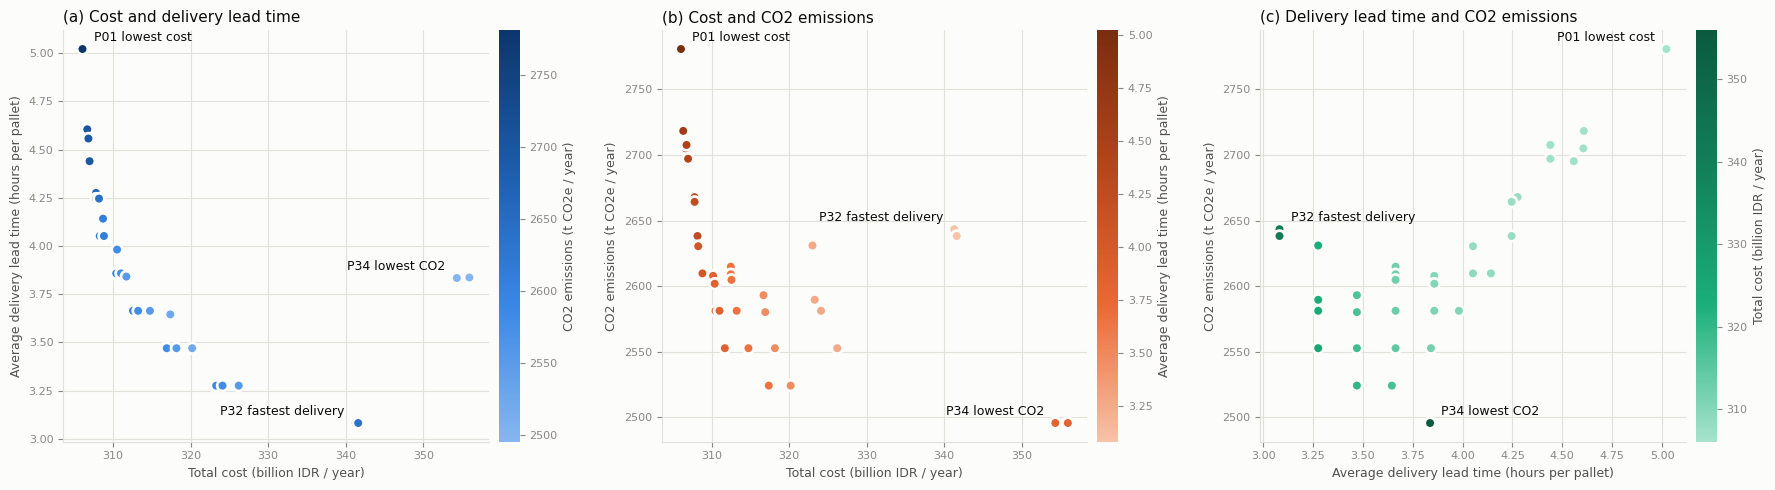

In [54]:
# ===== 2.7.1 HÌNH ĐƯỜNG PARETO =====
# 3 khung, mỗi khung 1 cặp mục tiêu, màu = mục tiêu còn lại:
#   (a) chi phí - thời gian giao, màu = CO2 | (b) chi phí - CO2, màu = thời gian giao | (c) thời gian giao - CO2, màu = chi phí
# Chữ trong hình bằng tiếng Anh để đưa thẳng vào luận văn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pareto = pd.read_parquet(OUT / "pareto.parquet")                         # tập Pareto đã lưu ở 2.6.4
print(pareto[["PhuongAn", "f1", "f2_gio", "f3", "SoKhoMo"]].head(10).round(2).to_string())

# --- Màu: mỗi khung một thang màu 1 sắc độ, nhạt -> đậm (xanh = CO2, cam = thời gian giao, xanh ngọc = chi phí) ---
XANH = LinearSegmentedColormap.from_list("xanh", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
CAM = LinearSegmentedColormap.from_list("cam", ["#f6c2a8", "#eb6834", "#b4461c", "#7a2d10"])
NGOC = LinearSegmentedColormap.from_list("ngoc", ["#a6e3cc", "#1baf7a", "#12805a", "#0b5a3f"])
NEN, CHU, PHU, MO, LUOI = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"   # nền, chữ chính, chữ phụ, nhãn trục, lưới

# --- 3 góc được ghi nhãn (phương án rẻ nhất trong số các phương án cùng đạt mức tốt nhất) ---
goc = {pareto.loc[pareto["f1"].idxmin(), "PhuongAn"]: "lowest cost",
       pareto[pareto["f2"] <= pareto["f2"].min() + 1e-4].sort_values("f1")["PhuongAn"].iloc[0]: "fastest delivery",   # rẻ nhất trong các phương án nhanh nhất
       pareto[pareto["f3"] <= pareto["f3"].min() + 1.0].sort_values("f1")["PhuongAn"].iloc[0]: "lowest CO2"}         # rẻ nhất trong các phương án ít CO2 nhất

TEN = {"f1": "Total cost (billion IDR / year)", "f2_gio": "Average delivery lead time (hours per pallet)",
       "f3": "CO2 emissions (t CO2e / year)"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), facecolor=NEN)
khung = [(axes[0], "f1", "f2_gio", "f3", XANH, "(a) Cost and delivery lead time"),
         (axes[1], "f1", "f3", "f2_gio", CAM, "(b) Cost and CO2 emissions"),
         (axes[2], "f2_gio", "f3", "f1", NGOC, "(c) Delivery lead time and CO2 emissions")]
for ax, x, y, mau, cmap, tieu_de in khung:
    diem = ax.scatter(pareto[x], pareto[y], c=pareto[mau], cmap=cmap, s=60,
                      edgecolors=NEN, linewidths=2, zorder=3)             # chấm cỡ vừa, viền màu nền để chấm chồng nhau vẫn tách
    cb = fig.colorbar(diem, ax=ax, pad=0.02)
    cb.set_label(TEN[mau], color=PHU, fontsize=9)
    cb.outline.set_visible(False)
    cb.ax.tick_params(colors=MO, labelsize=8)
    for pa, nhan in goc.items():                                         # nhãn trực tiếp chỉ cho 3 góc
        r = pareto[pareto["PhuongAn"] == pa].iloc[0]
        ben_phai = r[x] > pareto[x].median()                             # điểm bên phải: đặt nhãn sang trái cho khỏi tràn
        ax.annotate(f"{pa} {nhan}", (r[x], r[y]), xytext=(-8 if ben_phai else 8, 6), textcoords="offset points",
                    ha="right" if ben_phai else "left", fontsize=9, color=CHU)
    ax.set_title(tieu_de, loc="left", color=CHU, fontsize=11)
    ax.set_xlabel(TEN[x], color=PHU, fontsize=9)
    ax.set_ylabel(TEN[y], color=PHU, fontsize=9)
    ax.set_facecolor(NEN)
    ax.grid(True, color=LUOI, linewidth=0.8)
    ax.set_axisbelow(True)                                               # lưới nằm dưới chấm
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(LUOI)
    ax.tick_params(colors=MO, labelsize=8)
fig.tight_layout()

(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "pareto_front.png", dpi=200, bbox_inches="tight")
plt.show()

In [55]:
# ===== 2.7.1b HÌNH 3D TẬP PARETO (HIGHCHARTS) =====
# Highcharts = thư viện JavaScript mà highcharter (R) dùng bên dưới. Python không có highcharter nên ghi thẳng ra file HTML.
# Mở file bằng Chrome / Edge: kéo chuột để xoay, rê chuột vào chấm để xem số, menu ☰ góc phải để tải PNG chèn Word.
import json
from matplotlib.colors import LinearSegmentedColormap, to_hex
from IPython.display import HTML, display

pareto = pd.read_parquet(OUT / "pareto.parquet")                         # tập Pareto đã lưu ở 2.6.4

# --- 3 góc được ghi nhãn (phương án rẻ nhất trong số các phương án cùng đạt mức tốt nhất) ---
goc = {pareto.loc[pareto["f1"].idxmin(), "PhuongAn"]: "lowest cost",
       pareto[pareto["f2"] <= pareto["f2"].min() + 1e-4].sort_values("f1")["PhuongAn"].iloc[0]: "fastest delivery",
       pareto[pareto["f3"] <= pareto["f3"].min() + 1.0].sort_values("f1")["PhuongAn"].iloc[0]: "lowest CO2"}

# --- Màu chấm theo chi phí: xanh ngọc nhạt (rẻ) -> đậm (đắt), cùng thang màu với khung (c) của 2.7.1 ---
NGOC = LinearSegmentedColormap.from_list("ngoc", ["#a6e3cc", "#1baf7a", "#12805a", "#0b5a3f"])
chuan = (pareto["f1"] - pareto["f1"].min()) / (pareto["f1"].max() - pareto["f1"].min())   # chi phí đổi về 0..1

# --- Dữ liệu cho Highcharts: x = chi phí, y = thời gian giao (giờ), z = CO2 ---
diem = [{"x": round(r["f1"], 2), "y": round(r["f2_gio"], 3), "z": round(r["f3"], 1), "name": r["PhuongAn"],
         "kho": int(r["SoKhoMo"]), "color": to_hex(NGOC(c)),
         "dataLabels": {"enabled": r["PhuongAn"] in goc, "format": f"{r['PhuongAn']} {goc.get(r['PhuongAn'], '')}"}}
        for (_, r), c in zip(pareto.iterrows(), chuan)]
print(pd.DataFrame(diem)[["name", "x", "y", "z", "kho", "color"]].head(10).to_string())

cau_hinh = {
    "chart": {"type": "scatter3d", "height": 620, "backgroundColor": "#fcfcfb",
              "options3d": {"enabled": True, "alpha": 12, "beta": 30, "depth": 420, "viewDistance": 6,
                            "frame": {"bottom": {"size": 1, "color": "#f0efec"}, "back": {"size": 1, "color": "#f6f5f2"},
                                      "side": {"size": 1, "color": "#f6f5f2"}}}},
    "title": {"text": "Pareto set: cost, delivery lead time and CO2", "align": "left"},
    "subtitle": {"text": "Each dot is one Pareto network. Darker = more expensive. Drag to rotate.", "align": "left"},
    "xAxis": {"title": {"text": "Total cost (billion IDR / year)"}, "gridLineWidth": 1},
    "yAxis": {"title": {"text": "Lead time (hours / pallet)"}},
    "zAxis": {"title": {"text": "CO2 (t CO2e / year)"}, "showFirstLabel": False},
    "legend": {"enabled": False},
    "credits": {"enabled": False},
    "tooltip": {"headerFormat": "", "pointFormat": "<b>{point.name}</b><br>Cost: {point.x:.2f} B IDR/yr<br>"
                "Lead time: {point.y:.2f} h<br>CO2: {point.z:,.0f} t/yr<br>Open facilities: {point.kho}"},
    "plotOptions": {"scatter3d": {"marker": {"radius": 6, "lineWidth": 1, "lineColor": "#fcfcfb"},
                                  "dataLabels": {"style": {"fontSize": "11px", "fontWeight": "normal", "color": "#0b0b0b",
                                                           "textOutline": "2px #fcfcfb"}}}},
    "series": [{"name": "Pareto networks", "data": diem}],
}

# --- Trang HTML: nạp Highcharts từ CDN, vẽ hình, thêm kéo-để-xoay (theo ví dụ chính thức của Highcharts) ---
trang = f"""<!doctype html><html><head><meta charset="utf-8"><title>Pareto 3D</title>
<script src="https://code.highcharts.com/11.4.8/highcharts.js"></script>
<script src="https://code.highcharts.com/11.4.8/highcharts-3d.js"></script>
<script src="https://code.highcharts.com/11.4.8/modules/exporting.js"></script>
<script src="https://code.highcharts.com/11.4.8/modules/offline-exporting.js"></script>
</head><body style="margin:0;background:#fcfcfb;font-family:Arial,sans-serif">
<div id="hinh" style="max-width:1000px;margin:0 auto"></div>
<script>
const chart = Highcharts.chart('hinh', {json.dumps(cau_hinh)});
function batDauKeo(e) {{
  e = chart.pointer.normalize(e);
  const x0 = e.chartX, y0 = e.chartY, a0 = chart.options.chart.options3d.alpha, b0 = chart.options.chart.options3d.beta;
  const keo = Highcharts.addEvent(document, e.type === 'touchstart' ? 'touchmove' : 'mousemove', function (ev) {{
    ev = chart.pointer.normalize(ev);
    chart.update({{chart: {{options3d: {{alpha: a0 + (ev.chartY - y0) / 5, beta: b0 + (x0 - ev.chartX) / 5}}}}}}, undefined, undefined, false);
  }});
  const tha = Highcharts.addEvent(document, e.type === 'touchstart' ? 'touchend' : 'mouseup', function () {{ keo(); tha(); }});
}}
Highcharts.addEvent(chart.container, 'mousedown', batDauKeo);
Highcharts.addEvent(chart.container, 'touchstart', batDauKeo);
</script></body></html>"""

(OUT / "figures").mkdir(exist_ok=True)
(OUT / "figures" / "pareto_3d.html").write_text(trang, encoding="utf-8")
display(HTML(f'<iframe srcdoc="{trang.replace(chr(34), "&quot;")}" width="100%" height="660" style="border:0"></iframe>'))

  name       x      y       z  kho    color
0  P01  306.06  5.022  2780.9   35  #a6e3cc
1  P02  306.35  4.608  2718.4   37  #a4e2cb
2  P03  306.67  4.606  2705.1   38  #a1e1c9
3  P04  306.77  4.440  2707.7   37  #a1e1c9
4  P05  306.82  4.558  2695.3   39  #a1e1c9
5  P06  306.97  4.440  2697.2   37  #9fe1c8
6  P07  307.80  4.276  2667.9   39  #99dec4
7  P08  307.81  4.246  2664.3   39  #99dec4
8  P09  308.19  4.246  2638.2   40  #96ddc2
9  P10  308.28  4.052  2630.4   39  #94dcc1


C:\Users\Huong\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:447: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### 2.7.2 Trade-off analysis

*(nội dung)*

### 2.7.3 Network configuration of representative solutions

(a) Giải lại luồng hàng cho từng phương án Pareto với đúng các kho mở của nó (LP, vài giây mỗi phương án), lưu `Model Outputs/pareto_flows.parquet`. (b) Bản đồ mạng (deck.gl) ghi ra `Model Outputs/figures/network_map.html`, tự mở bằng trình duyệt: chọn phương án, rê chuột lên đường / kho / khách để xem số.

In [56]:
# ===== 2.7.3a LUỒNG HÀNG CỦA TỪNG PHƯƠNG ÁN PARETO =====
# 2.6.3 chỉ lưu danh sách kho mở. Để vẽ mạng: cố định đúng các kho mở của phương án, giải lại phần luồng hàng.
# Không còn biến 0/1 -> bài toán LP, vài giây mỗi phương án. Giữ f2, f3 không tệ hơn phương án gốc, min chi phí.
import time
from pyomo.opt import TerminationCondition as TC

pareto = pd.read_parquet(OUT / "pareto.parquet")                         # tập Pareto (2.6.4)

# --- Dọn phần mục tiêu / ràng buộc của 2.6.2 - 2.6.3 còn trong mô hình, thêm ràng buộc "giữ f2, f3" ---
for ten in ["Lex", "OBJ", "AugF2", "AugF3", "s2", "s3", "E2", "E3", "GiuF2", "GiuF3", "TranF2", "TranF3"]:
    if hasattr(m, ten):
            m.del_component(ten)
m.TranF2 = pyo.Param(mutable=True, initialize=1.0)                       # trần f2 = f2 của phương án (đổi mỗi vòng)
m.TranF3 = pyo.Param(mutable=True, initialize=1e6)                       # trần f3 = f3 của phương án
m.GiuF2 = pyo.Constraint(expr=m.f2 <= m.TranF2)
m.GiuF3 = pyo.Constraint(expr=m.f3 <= m.TranF3)
m.OBJ = pyo.Objective(expr=m.f1, sense=pyo.minimize)

solver = pyo.SolverFactory("appsi_highs")
solver.options["time_limit"] = 300

luong, kiem_tra = [], []
t_dau = time.time()
for _, r in pareto.iterrows():
    mo = set(r["KhoMo"].split(","))
    for j in J_dec:
        m.Y[j].fix(1 if j in mo else 0)                                  # cố định đúng các kho mở của phương án
    m.TranF2.value = r["f2"] + 1e-5                                      # nới rất nhẹ cho sai số làm tròn
    m.TranF3.value = r["f3"] + 1e-2
    kq = solver.solve(m, load_solutions=False)
    try:
        solver.load_vars()
    except RuntimeError:
        print(f"{r['PhuongAn']}: không giải lại được ({kq.solver.termination_condition})")
        continue
    kiem_tra.append({"PhuongAn": r["PhuongAn"], "f1_goc": r["f1"], "f1_lai": pyo.value(m.f1),
                     "f2_goc": r["f2"], "f2_lai": pyo.value(m.f2), "f3_goc": r["f3"], "f3_lai": pyo.value(m.f3)})
    luong += [(r["PhuongAn"], "kho->khach", j, k, pyo.value(m.X[j, k])) for (j, k) in A_lm if pyo.value(m.X[j, k]) > 1e-6]
    luong += [(r["PhuongAn"], "kho->kho", i, j, pyo.value(m.T[i, j])) for (i, j) in A_tr if pyo.value(m.T[i, j]) > 1e-6]
    print(f"{r['PhuongAn']}: f1 {r['f1']:.2f} -> {pyo.value(m.f1):.2f} | {time.time() - t_dau:,.0f} giây", flush=True)

for j in J_dec:
    m.Y[j].unfix()                                                       # trả mô hình về như cũ
m.del_component(m.GiuF2); m.del_component(m.GiuF3)

# --- Kiểm tra: chi phí giải lại không cao hơn bản gốc (có thể thấp hơn chút vì sai số 0,1% của solver) ---
kiem_tra = pd.DataFrame(kiem_tra)
kiem_tra["LechF1_%"] = (kiem_tra["f1_lai"] / kiem_tra["f1_goc"] - 1) * 100
print(kiem_tra.head(10).round(4).to_string())
print(f"Lệch chi phí lớn nhất: {kiem_tra['LechF1_%'].abs().max():.3f}%")

luong = pd.DataFrame(luong, columns=["PhuongAn", "Chang", "Tu", "Den", "Pallet"])
print(luong.head(10).round(2).to_string())
luong.to_parquet(OUT / "pareto_flows.parquet", index=False)

P01: f1 306.06 -> 306.06 | 9 giây
P02: f1 306.35 -> 306.35 | 35 giây
P03: f1 306.67 -> 306.67 | 46 giây
P04: f1 306.77 -> 306.77 | 75 giây
P05: f1 306.82 -> 306.82 | 111 giây
P06: f1 306.97 -> 306.97 | 129 giây
P07: f1 307.80 -> 307.80 | 146 giây
P08: f1 307.81 -> 307.81 | 153 giây
P09: f1 308.19 -> 308.19 | 164 giây
P10: f1 308.28 -> 308.28 | 174 giây
P11: f1 308.71 -> 308.71 | 189 giây
P12: f1 308.82 -> 308.82 | 201 giây
P13: f1 310.20 -> 310.19 | 224 giây
P14: f1 310.40 -> 310.40 | 236 giây
P15: f1 310.52 -> 310.52 | 253 giây
P16: f1 311.03 -> 311.03 | 263 giây
P17: f1 311.71 -> 311.71 | 274 giây
P18: f1 312.48 -> 312.48 | 295 giây
P19: f1 312.49 -> 312.49 | 312 giây
P20: f1 312.57 -> 312.57 | 322 giây
P21: f1 313.23 -> 312.87 | 332 giây
P22: f1 314.76 -> 314.76 | 365 giây
P23: f1 316.70 -> 316.70 | 388 giây
P24: f1 316.93 -> 316.92 | 399 giây
P25: f1 317.38 -> 317.38 | 439 giây
P26: f1 318.17 -> 318.17 | 490 giây
P27: f1 320.20 -> 320.19 | 515 giây
P28: f1 323.01 -> 322.44 | 548 gi

In [57]:
# ===== 2.8 BẢN ĐỌC ĐƯỢC: CSV + HÌNH VÀO Model Outputs/18-10-2027 VÀ Model Outputs/Mẹ =====
# Bảng -> CSV UTF-8 có BOM (Excel đọc đúng tiếng Việt), hình -> chép nguyên file. Không chép parquet vào Mẹ.
import shutil
MOM = OUT_IN / "Mẹ"
MOM.mkdir(exist_ok=True)

# Bảng kết quả: payoff, nhật ký AUGMECON2, tập Pareto, luồng hàng từng phương án
for ten in ["payoff", "augmecon_runs", "pareto", "pareto_flows"]:
    if (OUT / f"{ten}.parquet").exists():
        bang = pd.read_parquet(OUT / f"{ten}.parquet")
        for noi in [OUT, MOM]:
            bang.to_csv(noi / f"{ten}.csv", index=False, encoding="utf-8-sig")

# Hình: đường Pareto 2D, 3D, sơ đồ phân tầng (bản đồ mạng chép ở ô cuối, sau khi vẽ)
for ten in ["pareto_front.png", "pareto_3d.html", "network_structure.png"]:
    nguon = OUT / "figures" / ten if (OUT / "figures" / ten).exists() else OUT_IN / "figures" / ten
    if nguon.exists():
        for noi in [OUT, MOM]:
            shutil.copy2(nguon, noi / ten)

In [58]:
# ===== 2.7.3b BẢN ĐỒ MẠNG LƯỚI (deck.gl): CHỌN PHƯƠNG ÁN, RÊ CHUỘT XEM LUỒNG =====
# Ghi ra 1 file HTML chứa luồng hàng của MỌI phương án -> đổi phương án trong ô chọn là vẽ lại ngay (chạy bằng card đồ hoạ).
# Rê chuột lên đường: từ đâu -> đến đâu, bao nhiêu pallet/năm. Rê lên kho: loại kho, tổng pallet xuất. Rê lên khách: cầu.
# Kho vẽ bằng biểu tượng nhà kho (màu theo loại; kho đóng = viền xám). Khung kết quả (trái trên) luôn hiện; khung chú giải (trái dưới) thu gọn bằng nút −/+.
# File tự mở bằng trình duyệt (Chrome / Edge); cần có mạng để tải deck.gl và nền bản đồ (Esri World Light Gray, không cần key).
import json, webbrowser

pareto = pd.read_parquet(OUT / "pareto.parquet")
luong = pd.read_parquet(OUT / "pareto_flows.parquet")                    # luồng hàng từng phương án (2.7.3a)

# --- Tọa độ kho (facility_master) và nhóm khách (file lead time gốc, giống Validation_2 §2.13) ---
toa_kho = pd.read_parquet(IN / "facility_master.parquet",
                          columns=["LocationID", "FacilityType", "Latitude", "Longitude"]).set_index("LocationID")
toa_khach = (pd.read_parquet(RAW / "LeadTime_AllFlow.parquet",
                             columns=["DestinationID", "Latitude_Destination", "Longitude_Destination"])
             .drop_duplicates("DestinationID").set_index("DestinationID")
             .rename(columns={"Latitude_Destination": "Latitude", "Longitude_Destination": "Longitude"}))
assert set(K) <= set(toa_khach.index), "Có nhóm khách thiếu tọa độ"
toa_khach = toa_khach.loc[K]
print(toa_kho.head(10).to_string())

# --- Đánh số nút: kho trước, nhóm khách sau -> mỗi luồng chỉ cần lưu [số nút đi, số nút đến, pallet] cho nhẹ file ---
nut = pd.concat([toa_kho[["Latitude", "Longitude"]].assign(Loai=toa_kho["FacilityType"], Cau=0.0),
                 toa_khach[["Latitude", "Longitude"]].assign(Loai="Customer", Cau=d[K].values)])
so_nut = {ten: i for i, ten in enumerate(nut.index)}
nodes = [{"id": ten, "lon": round(r["Longitude"], 5), "lat": round(r["Latitude"], 5), "loai": r["Loai"], "cau": round(r["Cau"], 1)}
         for ten, r in nut.iterrows()]

# --- Mỗi phương án: chỉ tiêu, kho mở, luồng hàng ---
phuong_an = {}
for _, r in pareto.iterrows():
    lu = luong[luong["PhuongAn"] == r["PhuongAn"]]
    phuong_an[r["PhuongAn"]] = {
        "f1": round(r["f1"], 2), "gio": round(r["f2_gio"], 2), "f3": round(r["f3"], 0), "so_kho": int(r["SoKhoMo"]),
        "mo": [so_nut[j] for j in r["KhoMo"].split(",")],
        "luong": [[so_nut[a], so_nut[b], round(p, 1), 1 if c == "kho->kho" else 0]
                  for a, b, p, c in zip(lu["Tu"], lu["Den"], lu["Pallet"], lu["Chang"])]}
print(f"{len(phuong_an)} phương án | {len(luong):,} luồng hàng | {len(nodes):,} nút")

DU_LIEU = json.dumps({"nodes": nodes, "pa": phuong_an}, separators=(",", ":"))

trang = """<!doctype html><html><head><meta charset="utf-8"><title>Bản đồ mạng lưới</title>
<script src="https://unpkg.com/deck.gl@8.9.36/dist.min.js"></script>
<style>
 body{margin:0;font-family:Arial,sans-serif;background:#fcfcfb}
 #map{position:absolute;inset:0}
 .khung{position:absolute;left:12px;z-index:2;background:#fcfcfbee;padding:10px 14px;border-radius:8px;
        box-shadow:0 1px 4px #0003;font-size:13px;color:#0b0b0b}
 #ket_qua{top:12px;width:340px;padding:7px 10px;font-size:12px}
 #hang{display:flex;gap:4px;align-items:center;margin:4px 0 5px}
 #hang select{flex:1;font-size:12px;padding:1px}
 .mui{border:1px solid #e1e0d9;background:#fcfcfb;border-radius:4px;width:22px;height:20px;cursor:pointer;font-size:10px;padding:0}
 .mui:hover{background:#f0efec}
 #chi_tieu{display:grid;grid-template-columns:repeat(4,1fr);gap:4px}
 .so{background:#f6f5f2;border-radius:5px;padding:2px 5px}
 .so span{display:block;font-size:9.5px;color:#52514e;white-space:nowrap}
 .so b{font-size:13px}
 #chu_giai{bottom:24px;padding:6px 12px;font-size:12px;display:flex;align-items:center;gap:12px;max-width:calc(100% - 48px)}
 #dau{display:flex;align-items:center;gap:8px;white-space:nowrap}
 #noi_dung{display:flex;align-items:center;gap:14px;flex-wrap:wrap}
 #chu_thich{display:flex;align-items:center;gap:4px 12px;flex-wrap:wrap}
 #thu{border:1px solid #e1e0d9;background:#fcfcfb;border-radius:4px;width:24px;height:22px;cursor:pointer;font-size:15px;line-height:1}
 .muc{display:flex;align-items:center;gap:4px;color:#52514e;white-space:nowrap}
 .muc img{width:15px;height:15px}
 #ghi{font-size:10px;color:#898781}
</style></head><body>
<div id="map"></div>
<div id="ket_qua" class="khung">
 <b>Mạng lưới của phương án Pareto</b> <span style="color:#898781;font-size:10px">(phím ← → để đổi)</span>
 <div id="hang"><button id="truoc" class="mui" title="Phương án trước (←)">◀</button><select id="chon"></select><button id="sau" class="mui" title="Phương án sau (→)">▶</button></div>
 <div id="chi_tieu"></div>
</div>
<div id="chu_giai" class="khung">
 <div id="dau"><b>Chú giải</b><button id="thu" title="Thu gọn / mở rộng">−</button></div>
 <div id="noi_dung">
  <div id="chu_thich"></div>
  <div id="ghi">Rê chuột lên đường, kho hoặc khách để xem số liệu. Đường càng dày = càng nhiều pallet/năm. ·
   Nền bản đồ: Esri, HERE, Garmin, © OpenStreetMap contributors</div>
 </div>
</div>
<script>
const D = __DU_LIEU__;
const N = D.nodes;
const MAU = {"NDC":"#0b0b0b","RDC":"#2a78d6","DC Direct":"#eb6834","DC Satellite":"#1baf7a","DEPO":"#eda100"};

// --- Biểu tượng nhà kho (SVG): mái + thân + cửa cuốn; kho đóng = viền xám, ruột trắng ---
function iconKho(mau, mo) {
  const than = mo ? mau : '#fcfcfb', vien = mo ? '#fcfcfb' : '#898781', cua = mo ? '#fcfcfb' : '#e1e0d9';
  const svg = `<svg xmlns="http://www.w3.org/2000/svg" width="64" height="64" viewBox="0 0 32 32">
    <polygon points="2,14 16,4 30,14" fill="${than}" stroke="${vien}" stroke-width="1.6" stroke-linejoin="round"/>
    <rect x="5" y="14" width="22" height="15" fill="${than}" stroke="${vien}" stroke-width="1.6"/>
    <rect x="11" y="19" width="10" height="10" fill="${cua}" stroke="${vien}" stroke-width="0.8"/>
    <line x1="11" y1="22" x2="21" y2="22" stroke="${mo ? mau : '#898781'}" stroke-width="0.8"/>
    <line x1="11" y1="25" x2="21" y2="25" stroke="${mo ? mau : '#898781'}" stroke-width="0.8"/></svg>`;
  return 'data:image/svg+xml;charset=utf-8,' + encodeURIComponent(svg);
}
const ICON = {};
Object.entries(MAU).forEach(([loai, mau]) => { ICON[loai] = iconKho(mau, true); });
const ICON_DONG = iconKho('#898781', false);

// --- Chú thích ---
document.getElementById('chu_thich').innerHTML =
  Object.keys(MAU).map(l => `<div class="muc"><img src="${ICON[l]}">${l}</div>`).join('') +
  `<div class="muc"><img src="${ICON_DONG}">kho đóng</div>` +
  `<div class="muc"><span style="display:inline-block;width:18px;height:3px;background:#0d366b"></span>kho → kho</div>` +
  `<div class="muc"><span style="display:inline-block;width:18px;height:1px;background:#5598e7"></span>kho → khách</div>`;

// --- Nút thu gọn / mở rộng bảng ---
document.getElementById('thu').addEventListener('click', e => {
  const nd = document.getElementById('noi_dung'), an = nd.style.display !== 'none';
  nd.style.display = an ? 'none' : 'flex';
  e.target.textContent = an ? '+' : '−';
});

// --- Ô chọn phương án ---
const chon = document.getElementById('chon');
Object.entries(D.pa).forEach(([k, v]) => {
  const o = document.createElement('option'); o.value = k;
  o.textContent = `${k} · ${v.f1.toFixed(1)} tỷ IDR · ${v.gio.toFixed(2)} giờ · ${v.f3.toLocaleString('vi-VN')} tấn`;
  chon.appendChild(o);
});

const nen = new deck.TileLayer({
  id: 'nen', data: 'https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}',
  minZoom: 0, maxZoom: 16, tileSize: 256,
  renderSubLayers: props => {
    const {bbox: {west, south, east, north}} = props.tile;
    return new deck.BitmapLayer(props, {data: null, image: props.data, bounds: [west, south, east, north]});
  }
});

function lop(ma) {
  const pa = D.pa[ma];
  const mo = new Set(pa.mo);
  const xuat = {};                                       // tổng pallet xuất khỏi mỗi kho
  pa.luong.forEach(([a, b, p]) => { xuat[a] = (xuat[a] || 0) + p; });
  const luong = pa.luong.map(([a, b, p, c]) => ({a: N[a], b: N[b], p, c}));
  const kho = N.map((n, i) => ({...n, i})).filter(n => n.loai !== 'Customer');
  const khach = N.filter(n => n.loai === 'Customer');
  document.getElementById('chi_tieu').innerHTML =
    `<div class="so"><span>Chi phí (tỷ/năm)</span><b>${pa.f1.toFixed(2)}</b></div>` +
    `<div class="so"><span>Giao TB (giờ)</span><b>${pa.gio.toFixed(2)}</b></div>` +
    `<div class="so"><span>CO2 (tấn/năm)</span><b>${pa.f3.toLocaleString('vi-VN')}</b></div>` +
    `<div class="so"><span>Số kho mở</span><b>${pa.so_kho}</b></div>`;
  return [
    nen,
    new deck.ScatterplotLayer({id: 'khach', data: khach, pickable: true, getPosition: d => [d.lon, d.lat],
      getRadius: d => Math.sqrt(d.cau) * 250, radiusMinPixels: 1.5, radiusMaxPixels: 8,
      getFillColor: [160, 158, 150, 160]}),
    new deck.LineLayer({id: 'last', data: luong.filter(l => !l.c), pickable: true,
      getSourcePosition: l => [l.a.lon, l.a.lat], getTargetPosition: l => [l.b.lon, l.b.lat],
      getColor: [85, 152, 231, 140], getWidth: l => 0.4 + Math.sqrt(l.p) / 40, widthUnits: 'pixels'}),
    new deck.LineLayer({id: 'transfer', data: luong.filter(l => l.c), pickable: true,
      getSourcePosition: l => [l.a.lon, l.a.lat], getTargetPosition: l => [l.b.lon, l.b.lat],
      getColor: [13, 54, 107, 210], getWidth: l => 1 + Math.sqrt(l.p) / 30, widthUnits: 'pixels'}),
    new deck.IconLayer({id: 'kho_dong', data: kho.filter(k => !mo.has(k.i)), pickable: true,
      getPosition: d => [d.lon, d.lat], getSize: 20, sizeUnits: 'pixels',
      getIcon: d => ({url: ICON_DONG, id: 'dong', width: 64, height: 64, anchorY: 40})}),
    new deck.IconLayer({id: 'kho_mo', data: kho.filter(k => mo.has(k.i)).map(k => ({...k, xuat: xuat[k.i] || 0})),
      pickable: true, getPosition: d => [d.lon, d.lat], sizeUnits: 'pixels',
      getSize: d => (d.loai === 'NDC' || d.loai === 'RDC') ? 32 : 24,
      getIcon: d => ({url: ICON[d.loai], id: d.loai, width: 64, height: 64, anchorY: 40})}),
  ];
}

const ban_do = new deck.DeckGL({
  container: 'map', controller: {keyboard: false}, pickingRadius: 6,      // phím mũi tên dùng để đổi phương án, không kéo bản đồ
  initialViewState: {longitude: 117.5, latitude: -2.5, zoom: 4.2},
  layers: lop(chon.value),
  getTooltip: ({object, layer}) => {
    if (!object) return null;
    const fmt = x => Math.round(x).toLocaleString('vi-VN');
    if (layer.id === 'last' || layer.id === 'transfer')
      return {text: `${object.a.id} → ${object.b.id}\\n${fmt(object.p)} pallet/năm\\n` +
                    (object.c ? 'kho → kho' : 'kho → khách')};
    if (layer.id === 'kho_mo') return {text: `${object.id} (${object.loai}, đang mở)\\nXuất ${fmt(object.xuat)} pallet/năm`};
    if (layer.id === 'kho_dong') return {text: `${object.id} (${object.loai}, đóng)`};
    if (layer.id === 'khach') return {text: `Nhóm khách hàng\\nCầu ${fmt(object.cau)} pallet/năm`};
    return null;
  }
});
chon.addEventListener('change', () => { ban_do.setProps({layers: lop(chon.value)}); chon.blur(); });

// --- Đổi phương án bằng nút ◀ ▶ hoặc phím ← → ---
function doi(buoc) {
  const i = chon.selectedIndex + buoc;
  if (i < 0 || i >= chon.options.length) return;          // đã ở đầu / cuối danh sách
  chon.selectedIndex = i;
  ban_do.setProps({layers: lop(chon.value)});
}
document.getElementById('truoc').addEventListener('click', () => doi(-1));
document.getElementById('sau').addEventListener('click', () => doi(1));
document.addEventListener('keydown', e => {
  if (e.key === 'ArrowLeft') { e.preventDefault(); doi(-1); }
  if (e.key === 'ArrowRight') { e.preventDefault(); doi(1); }
});
</script></body></html>""".replace("__DU_LIEU__", DU_LIEU)

(OUT / "figures").mkdir(exist_ok=True)
duong_dan = (OUT / "figures" / "network_map.html").resolve()
duong_dan.write_text(trang, encoding="utf-8")
print(f"Đã lưu: {duong_dan} ({duong_dan.stat().st_size / 1e6:.1f} MB)")
webbrowser.open(duong_dan.as_uri())                                      # mở bằng trình duyệt mặc định

            FacilityType  Latitude   Longitude
LocationID                                    
D03         DC Satellite -8.639276  115.180281
D06                  RDC -3.410360  114.670591
D09            DC Direct -6.458121  106.855151
D10                  RDC -6.773010  108.518292
D16                  RDC  3.535290   98.734113
D18                  RDC -2.933271  104.733908
D20            DC Direct -0.099762  109.407724
D25            DC Direct -7.539930  110.728928
D26            DC Direct -7.345353  112.757605
D30                  RDC -7.831725  111.994648
35 phương án | 118,724 luồng hàng | 3,399 nút
Đã lưu: D:\ĐẠI HỌC\KLTN - Phuc1\Data\Model Outputs\18-10-2027\figures\network_map.html (2.2 MB)


True

In [59]:
# # ===== KIỂM TRA: mỗi DEPO nhận bao nhiêu tấn / ngày (P22) - có đủ đầy xe 4 tấn không? =====
# import pandas as pd
# from pathlib import Path
# IN, OUT = Path("../Model - Data used"), Path("../Model Outputs")          # giống ô đầu notebook

# # Loại kho theo mã kho (để lọc các tuyến đi vào DEPO)
# loai_kho = pd.read_parquet(IN / "facility_master.parquet",
#                            columns=["LocationID", "FacilityType"]).set_index("LocationID")["FacilityType"]
# # Tấn / pallet trung bình, giống W_TB ở ô 2.3.3
# dem = pd.read_parquet(OUT / "demand.parquet")
# W_TB = dem["Ton"].sum() / dem["DemandPallet"].sum()

# # Các tuyến kho -> DEPO có hàng trong P22
# luong = pd.read_parquet(OUT / "pareto_flows.parquet")
# vao = luong[(luong["PhuongAn"] == "P22") & (luong["Chang"] == "kho->kho")]
# vao = vao[vao["Den"].map(loai_kho) == "DEPO"]

# # Tổng pallet / năm mỗi DEPO nhận -> đổi ra tấn / ngày (360 ngày / năm)
# bang = vao.groupby("Den")["Pallet"].sum().to_frame("Pallet_nam")
# bang["Tan_ngay"] = bang["Pallet_nam"] * W_TB / 360
# bang["Ty_le_xe_4t_%"] = bang["Tan_ngay"] / (4 * 0.85) * 100                # so với 1 xe 4 tấn chở 85%

# print(f"Tấn / pallet trung bình: {W_TB:.3f}")
# print(bang.sort_values("Tan_ngay").round(2).head(10).to_string())         # 10 DEPO nhận ít nhất
# print(f"\nSố DEPO nhận < 1 tấn/ngày: {(bang['Tan_ngay'] < 1).sum()} / {len(bang)}")


In [60]:
# # ===== KIỂM TRA: từng tuyến DC -> DEPO, mọi phương án - xe chở bao nhiêu / ngày? =====
# tuyen = luong[(luong["Chang"] == "kho->kho") & (luong["Den"].map(loai_kho) == "DEPO")].copy()
# tuyen["LoaiTu"] = tuyen["Tu"].map(loai_kho)                                # kho cấp hàng là loại gì (NDC/RDC/DC...)
# tuyen["Tan_ngay"] = tuyen["Pallet"] * W_TB / 360                           # tấn / ngày trên tuyến này
# tuyen["Ty_le_xe_4t_%"] = tuyen["Tan_ngay"] / (4 * 0.85) * 100              # so với 1 xe 4 tấn chở 85%

# # (a) Mỗi DEPO nhận hàng từ mấy kho? (> 1 nghĩa là hàng bị chia ra nhiều tuyến)
# so_nguon = tuyen.groupby(["PhuongAn", "Den"])["Tu"].nunique()
# print(f"DEPO nhận từ > 1 kho: {(so_nguon > 1).sum()} / {len(so_nguon)} (cặp phương án - DEPO)")

# # (b) Ví dụ 1 DEPO: đổi phương án thì lấy hàng từ kho nào, bao nhiêu
# print("\nVí dụ DEPO05 qua các phương án:")
# print(tuyen[tuyen["Den"] == "DEPO05"][["PhuongAn", "Tu", "LoaiTu", "Pallet", "Tan_ngay"]]
#       .round(2).head(10).to_string(index=False))

# # (c) Tóm tắt theo loại kho cấp hàng: tuyến chở bao nhiêu / ngày
# print("\nTheo loại kho cấp hàng (mọi phương án):")
# print(tuyen.groupby("LoaiTu")["Tan_ngay"].describe()[["count", "min", "50%", "max"]].round(2).to_string())
# print(f"\nTuyến chở < 1 tấn/ngày: {(tuyen['Tan_ngay'] < 1).mean() * 100:.0f}% số tuyến")


In [61]:
# ===== 2.8b CHÉP BẢN ĐỒ MẠNG LƯỚI VÀO THƯ MỤC KẾT QUẢ VÀ Mẹ =====
import shutil
if (OUT / "figures" / "network_map.html").exists():
    for noi in [OUT, OUT_IN / "Mẹ"]:
        shutil.copy2(OUT / "figures" / "network_map.html", noi / "network_map.html")